![Banner](../../../../Images/Banner/07_remote_sensing/09_13_banner_rs_capstones.png)


# Charland Monitoring with Sentinel-1 SAR (and NISAR L-band), Lower Meghna Estuary of Bangladesh

Charlands (*char*) are low islands and bars of sand and silt that the Ganges-Brahmaputra-Meghna system builds, reshapes and removes within a few years.


## Overview

This capstone implements the **Charland Monitoring Protocol: Sentinel-1 SAR** step by step on the local data in `Data/08_remote_sensing/08_11_Capstones/s1_BD_charland/`:

| Protocol objective | Where in this notebook |
|---|---|
| 1. Classify every Sentinel-1 acquisition into water and non-water | Steps 3 to 5 |
| 2. Combine classified scenes into annual, tide-adjusted land-frequency maps | Steps 6 and 7 |
| 3. Measure accretion, erosion and net land change, for the AOI and for each char | Steps 8, 10, 11 |
| 4. Track char maturity (intertidal flat → bare land → vegetated land) from backscatter | Step 9 |
| 5. Report accuracy against independent reference data | Step 14 |

NISAR L-band GCOV scenes in `Data/08_remote_sensing/08_11_Capstones/s1_BD_charland/NISAR_BD/` are processed as a **separate, parallel series** (Step 13), as the protocol requires for any second track or sensor.


### What the local data can and cannot support

The local archive holds **20 Sentinel-1A IW GRDH scenes** from one track (relative orbit 114, ascending, about 12:04 UTC) and **5 NISAR GCOV scenes for July to October 2026**:

| Dry-season year (Dec–Mar) | Scenes |
|---|---|
| `dry_2024` | Dec 2023, Jan, Feb, Mar 2024 |
| `dry_2025` | Dec 2024, Jan, Feb, Mar 2025 |
| `dry_2026` | Dec 2025, Jan, Feb, Mar 2026 |
| Rest of 2024 | one scene a month, April to November |

- **Three complete dry seasons** (Bangladesh dry season, December to March; December is counted with the following year). This gives two protocol annual change pairs, **dry 2024 → dry 2025** and **dry 2025 → dry 2026**. The first pair can be confirmed by the next season's map, and the second by the low- and mid-tide composites of 2026. The char register, shoreline transects and pixel history run over the three dry seasons.
- **2024 is the only full calendar year.** It supplies the monsoon map, the post-monsoon (November-December) map, char maturity (which needs the seasonal VH swing) and a within-year **dry 2024 → November-December 2024** comparison. That comparison is kept as a descriptive view of the 2024 monsoon.
- **Four scenes per dry season** is below the protocol's five low-tide scenes, so the low-tide composites rest on one or two scenes each and the release stays provisional on that item.
- The tide model (FES/TPXO via `pyTMD`), BIWTA gauge records, ERA5 wind, Sentinel-2 reference imagery and union boundaries are **not in the folder**. The notebook uses them automatically when you add them (paths in the Parameters cell). Until then it uses transparent SAR-based proxies (a water-level index for tide, open-water VV for wind) and marks the release provisional.
- Precise orbit files and a GLO-30 DEM are not supplied. Scenes are geocoded with the products' own geolocation grid (ellipsoid). On this flat coast (mostly below 5 m) the residual terrain displacement is under one 10 m pixel and identical on every date of the same track, so it does not create false change.

Every place where the notebook departs from the protocol because of missing inputs is stated where it happens and collected again in the QA checklist (Step 15).


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README. It also uses `ipyleaflet`, which no GeoLattice option installs: `pip install ipyleaflet`.

In [ ]:
# Setup. Libraries, the geolattice.rsense SAR toolkit, and plotting defaults.

# 1. Silence harmless rasterio/xarray warnings that ordinary reads trigger.
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# 2. Standard library helpers.
import base64, json, math, os, time
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta
from pathlib import Path

# 3. Scientific, vector and raster libraries used throughout.
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
import rasterio
from rasterio.enums import Resampling
from rasterio.features import geometry_mask, shapes
from rasterio.transform import Affine
from rasterio.warp import reproject, transform_bounds
from scipy import ndimage as ndi
import shapely
from shapely.geometry import LineString, Point, mapping, shape
from shapely.ops import unary_union
from shapely.strtree import STRtree
from skimage.filters import threshold_otsu

# 4. geolattice.rsense: SAFE indexing, GRD calibration/subsetting, co-registered stacks,
#    speckle filters, morphology helpers and Olofsson accuracy assessment.
import geolattice.rsense as rs
from geolattice.rsense.core.io import read_safe
from geolattice.rsense.core.morphology import fill_small_holes, remove_small
from geolattice.rsense.classify.accuracy import accuracy_report, olofsson

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rs.set_backend("cpu")
print("geolattice.rsense:", rs.__version__)

geolattice.rsense: 0.2.0.dev0


## Parameters

All settings that the protocol fixes, plus the optional ancillary files, are collected here. Values marked *protocol* come straight from the protocol; the rest are working choices explained in the comments.

**Optional ancillary inputs.** Put any of these in `Data/08_remote_sensing/08_11_Capstones/s1_BD_charland/` and re-run; the notebook picks them up:

| File | Columns / content | Replaces |
|---|---|---|
| `scene_tide.csv` | `date` (YYYY-MM-DD), `tide_m` (m above MSL), e.g. BIWTA Khepupara/Char Changa | SAR water-level index |
| `PYTMD_MODEL_DIR` environment variable | folder with FES2014/FES2022 or TPXO model files for `pyTMD` | SAR water-level index |
| `era5_wind.csv` | `date`, `wind_ms` (ERA5 10 m wind at the acquisition hour) | open-water VV wind proxy |
| `unions.gpkg` | union polygons with a `name` column (BBS/LGED) | AOI-only statistics |
| `validation/ref_points_*.gpkg` | the sample files this notebook writes, with `ref_class` filled in | provisional status |


In [ ]:
# Parameters. Paths, grid, seasons, thresholds and QA rules.

# 1. Input locations (run this notebook from the 08_11_Capstones folder).
DATA_DIR = Path("../../../../Data/08_remote_sensing/08_11_Capstones/s1_BD_charland")
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Run this notebook from the 08_11_Capstones folder; missing {DATA_DIR}")
S1_DIR = DATA_DIR / "Sentinel_1"
NISAR_DIR = DATA_DIR / "NISAR_BD"
AOI_PATH = DATA_DIR / "charland_aoi.geojson"

# 2. Output folders, following the protocol's folder layout.
OUT = {name: DATA_DIR / name for name in
       ["preprocessed", "classified", "annual", "change", "vectors", "validation", "reports"]}
RAW_DIR = OUT["preprocessed"] / "raw"            # unfiltered linear sigma0 (for Quegan and texture)
NISAR_OUT = OUT["preprocessed"] / "nisar"
FIG_DIR = OUT["reports"] / "figures"
for folder in [*OUT.values(), RAW_DIR, NISAR_OUT, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
OVERWRITE = False          # True re-runs preprocessing/classification even if outputs exist

# 3. Master grid (protocol): UTM 46N at 10 m. Set 20 or 30 m for a quicker first run;
#    every threshold below that is given in hectares or metres adapts automatically.
GRID_CRS = "EPSG:32646"
RESOLUTION_M = 10.0
READ_MARGIN_PX = 100       # 1 km buffer around the AOI when cutting the GRD window (protocol)

# 4. Hydrological seasons (protocol). Dry-season years run December to March, so
#    December is counted with the following year.
DRY_MONTHS = (12, 1, 2, 3)
PRE_MONSOON_MONTHS = (4, 5)
MONSOON_MONTHS = (6, 7, 8, 9, 10)
POST_MONSOON_MONTHS = (11,)

# 5. Scene selection and flags (protocol).
MIN_AOI_COVER = 0.95                     # keep scenes covering at least 95% of the AOI
WIND_LIMIT_MS = 7.0                      # ERA5 wind above this excludes a scene from composites
ROUGH_WATER_VV_DB = -15.0                # water brighter than this in VV: check with VH / wind proxy
CYCLONE_LANDFALLS = {"Remal": "2024-05-26"}   # named cyclones with Bangladesh landfall in the archive
CYCLONE_EXCLUDE_DAYS = 3
MAX_DRIFT_PX = 1.0                       # coregistration drift limit against the master
RFI_REJECT = []                          # dates (YYYY-MM-DD) rejected after the quick-look review

# 6. Per-scene classification (protocol).
TILE_PX = int(round(2560 / RESOLUTION_M))     # 2.56 km tiles (256 px at 10 m)
TILE_MIN_FRAC = 0.10                     # each class must hold 10-90% of a tile
TILE_MIN_SEP_DB = 3.0                    # and the two class means must differ by 3 dB (bimodality)
THRESHOLD_METHOD = "otsu"                # "otsu" or "ki" (Kittler-Illingworth)
DEFAULT_THRESHOLD_DB = -16.0             # used only if no bimodal tile is found (flagged)
UNCERTAIN_BAND_DB = 2.0                  # |VV - threshold| < 2 dB -> uncertain (wet mud)
MIN_OBJECT_PX = max(1, int(round(5000 / RESOLUTION_M**2)))   # 0.5 ha cleaning size
RESOLVE_UNCERTAIN = "exclude"            # "exclude" (protocol skeleton) or "rf" (Random Forest)

# 7. Land frequency classes (protocol).
FREQ_WATER = 0.10                        # < 10% land -> permanent water
FREQ_LAND = 0.90                         # >= 90% land -> stable land
MIN_LOWTIDE_SCENES = 5                   # QA: low-tide composite built from >= 5 scenes
DRY_SEASON_MIN_SCENES = 3                # a dry season with fewer scenes is "incomplete"
FULL_YEAR_MIN_MONTHS = 10                # year_YYYY maps only for calendar years with scenes in >= 10 months

# 8. Tide and wind ancillary data (optional; see the table above).
TIDE_CSV = DATA_DIR / "scene_tide.csv"
ERA5_CSV = DATA_DIR / "era5_wind.csv"
TIDE_MODEL_DIR = os.environ.get("PYTMD_MODEL_DIR")
TIDE_MODEL = "FES2022"
TIDE_POINT = (90.55, 21.76)              # lon, lat: open water at the AOI's south edge
UNIONS_PATH = DATA_DIR / "unions.gpkg"

# 9. Char register, maturity and shoreline settings (protocol).
CHAR_MIN_PX = max(1, int(round(10000 / RESOLUTION_M**2)))    # 1 ha
TRANSECT_SPACING_M = 250
TRANSECT_HALF_LEN_M = 1500
MATURITY = {                              # starting values; calibrate against VHR imagery
    "wet_band_db": 3.0,       # bare wet sediment: dry-season VV within 3 dB above the scene threshold
    "veg_rise_db": 3.0,       # grass/crop: VH max >= bare baseline + 3 dB (protocol)
    "veg_swing_db": 3.0,      # ... with a seasonal VH swing of at least 3 dB
    "woody_vh_min_db": -17.0, # woody/mangrove: VH stays above this all year
    "settlement_vv_db": 0.0,  # settlement: bright VV double bounce
}

# 10. Validation design (protocol) and targets.
N_PER_CLASS = 50
N_SCENES_VALIDATE = 10
TARGETS = {"single_date_oa": 0.90, "single_date_water_f1": 0.90, "annual_oa": 0.85,
           "change_ua": 0.75, "waterline_median_m": 20.0}

# 11. NISAR parallel series.
NISAR_MIN_COVER = 0.95
GCOV_GRID = "/science/LSAR/GCOV/grids/frequencyA"

DISPLAY_STEP = max(1, int(round(40 / RESOLUTION_M)))   # plot at about 40 m to keep figures light
RNG = np.random.default_rng(42)
print(f"Grid {GRID_CRS} at {RESOLUTION_M:g} m | tiles {TILE_PX} px | cleaning {MIN_OBJECT_PX} px | chars >= {CHAR_MIN_PX} px")

Grid EPSG:32646 at 10 m | tiles 256 px | cleaning 50 px | chars >= 100 px


## Study area and master grid

The AOI is the 130 km × 53 km rectangle on the Barisal-Bhola coast given in the protocol. The master grid is the AOI's bounding box in UTM 46N, snapped to whole multiples of the pixel size, so every Sentinel-1 date and every NISAR date lands on exactly the same pixels. Pixels outside the AOI polygon are masked.


In [ ]:
# Load the AOI, build the master grid, and rasterize the AOI mask on it.

# 1. AOI polygon in WGS84 and its bounds (west, south, east, north).
aoi = gpd.read_file(AOI_PATH).to_crs("EPSG:4326")
AOI_BOUNDS = tuple(float(v) for v in aoi.total_bounds)
aoi_utm = aoi.to_crs(GRID_CRS)

# 2. Master grid: rs.sar.common_grid snaps the projected bounds to the pixel size; this is
#    the same function create_stack uses, so every scene stacked later matches it exactly.
GRID_TRANSFORM, GRID_W, GRID_H = rs.sar.common_grid(AOI_BOUNDS, GRID_CRS, RESOLUTION_M)
aoi_inside = geometry_mask([mapping(g) for g in aoi_utm.geometry], out_shape=(GRID_H, GRID_W),
                           transform=GRID_TRANSFORM, invert=True)
PIXEL_KM2 = RESOLUTION_M**2 / 1e6
MAP_EXTENT = (GRID_TRANSFORM.c, GRID_TRANSFORM.c + GRID_TRANSFORM.a * GRID_W,
              GRID_TRANSFORM.f + GRID_TRANSFORM.e * GRID_H, GRID_TRANSFORM.f)

print("AOI bounds (W, S, E, N):", tuple(round(v, 6) for v in AOI_BOUNDS))
print(f"AOI area: {aoi_utm.area.sum() / 1e6:,.0f} km²")
print(f"Master grid: {GRID_W:,} × {GRID_H:,} pixels ({GRID_W * GRID_H / 1e6:.1f} M), "
      f"{int(aoi_inside.sum()):,} inside the AOI")

AOI bounds (W, S, E, N): (89.91936, 21.740248, 91.181984, 22.221259)
AOI area: 6,951 km²
Master grid: 13,130 × 5,537 pixels (72.7 M), 69,511,210 inside the AOI


In [ ]:
# Interactive check of the AOI on satellite imagery (needs leafmap; skipped if not installed).
try:
    import leafmap
    west, south, east, north = AOI_BOUNDS
    aoi_map = leafmap.Map(center=((south + north) / 2, (west + east) / 2), zoom=9, height="520px")
    aoi_map.add_basemap("Esri.WorldImagery")
    aoi_map.add_gdf(aoi, layer_name="Charland AOI",
                    style={"color": "#ff3b30", "weight": 3, "fillOpacity": 0.05})
    display(aoi_map)
except ImportError:
    print("leafmap is not installed; skipping the interactive map.")

Map(center=[21.9807535, 90.55067199999999], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_i…

### Shared helpers

Small functions used by every later step: writing and reading rasters on the master grid (tiled, compressed GeoTIFFs with internal overviews), processing large arrays in row blocks so a 10 m grid of about 70 million pixels fits in memory, and drawing maps in UTM coordinates with the AOI outline.


In [ ]:
# Helpers: raster I/O on the master grid, blockwise processing, and map display.

def write_raster(path, bands, *, dtype, nodata, names=None):
    # Write one or more 2-D arrays on the master grid as a tiled, compressed GeoTIFF with overviews.
    bands = list(bands) if isinstance(bands, (list, tuple)) else [bands]
    kind = np.dtype(dtype).kind
    profile = dict(driver="GTiff", height=GRID_H, width=GRID_W, count=len(bands), dtype=dtype,
                   crs=GRID_CRS, transform=GRID_TRANSFORM, nodata=nodata, tiled=True,
                   blockxsize=512, blockysize=512, compress="deflate",
                   predictor=3 if kind == "f" else 2, BIGTIFF="IF_SAFER")
    with rasterio.open(path, "w", **profile) as dst:
        for i, band in enumerate(bands, start=1):
            dst.write(np.asarray(band).astype(dtype), i)
            if names:
                dst.set_band_description(i, names[i - 1])
        dst.build_overviews([2, 4, 8, 16], Resampling.nearest if kind != "f" else Resampling.average)
    return path

def read_band(path, band=1, step=1):
    # Read one band (optionally decimated through the overviews); float NoData becomes NaN.
    with rasterio.open(path) as src:
        shape_out = (src.height // step, src.width // step) if step > 1 else None
        arr = src.read(band, out_shape=shape_out, resampling=Resampling.nearest)
        nodata = src.nodata
    if arr.dtype.kind == "f":
        arr = arr.astype("float32")
        if nodata is not None and np.isfinite(nodata):
            arr[arr == nodata] = np.nan
    return arr

def blockwise(fn, arr, block=2048, halo=16):
    # Apply a neighbourhood filter in row blocks with a halo, so edges between blocks are exact.
    arr = np.asarray(arr)
    out = np.empty(arr.shape, dtype="float32")
    H = arr.shape[-2]
    for r0 in range(0, H, block):
        r1 = min(H, r0 + block)
        a0, a1 = max(0, r0 - halo), min(H, r1 + halo)
        res = np.asarray(fn(arr[..., a0:a1, :]))
        out[..., r0:r1, :] = res[..., r0 - a0:r0 - a0 + (r1 - r0), :]
    return out

def refined_lee_2d(lin):
    # Refined Lee 7x7 (protocol, single-scene maps) on a large linear-power image.
    return blockwise(lambda a: rs.sar.refined_lee(a), lin)

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=110, bbox_inches="tight")

def show_map(ax, values, *, cmap="gray", vmin=None, vmax=None, norm=None, title=None, step=None):
    # Draw a master-grid raster (decimated for display) in UTM coordinates with the AOI outline.
    step = step or DISPLAY_STEP
    v = values[::step, ::step] if values.shape == (GRID_H, GRID_W) else values
    im = ax.imshow(np.ma.masked_invalid(v.astype("float32")), extent=MAP_EXTENT, origin="upper",
                   interpolation="nearest", cmap=cmap, vmin=vmin, vmax=vmax, norm=norm)
    aoi_utm.boundary.plot(ax=ax, color="cyan", linewidth=0.6, zorder=4)
    ax.set_xlim(MAP_EXTENT[0], MAP_EXTENT[1]); ax.set_ylim(MAP_EXTENT[2], MAP_EXTENT[3])
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    if title:
        ax.set_title(title, fontsize=9)
    return im

def categorical(codes, colors):
    # Colormap and norm for integer class codes 0..n-1 (255 = NoData is masked separately).
    cmap = ListedColormap(colors)
    return cmap, BoundaryNorm(np.arange(-0.5, len(colors) + 0.5), cmap.N)

def masked_codes(arr):
    out = arr.astype("float32")
    out[arr == 255] = np.nan
    return out

CLASS_NAMES = {0: "Permanent water", 1: "Intertidal", 2: "Stable land"}
CLASS_COLORS = ["#1f4e79", "#e0b04a", "#3f7f3f"]
WATER_NAMES = {0: "Water", 1: "Land", 2: "Uncertain"}
WATER_COLORS = ["#1f4e79", "#c9b37e", "#d9534f"]
print("Helpers ready.")

Helpers ready.


## Scene inventory and selection

Each `.SAFE` manifest gives the pass direction, relative and absolute orbit, and the scene footprint; the annotation geolocation grid gives the incidence-angle range over the AOI. The protocol's selection rules are then applied:

- one relative orbit and pass for every product (a second track would only be used as a separate, parallel series);
- at least 95% AOI coverage;
- a cyclone flag for scenes within 3 days after a named cyclone landfall (Cyclone Remal made landfall on the Bangladesh-West Bengal coast on 26 May 2024; the nearest scene, 17 May, is before it).


In [ ]:
# Catalogue every SAFE scene: time, platform, orbit, pass, AOI cover, incidence range, season.

def manifest_info(safe_path):
    # Pass, relative/absolute orbit and footprint polygon from manifest.safe.
    root = ET.parse(safe_path / "manifest.safe").getroot()
    out = {}
    for el in root.iter():
        tag = el.tag.rsplit("}", 1)[-1]
        if tag == "pass" and el.text:
            out["pass"] = el.text.strip().upper()
        elif tag == "relativeOrbitNumber" and el.attrib.get("type") == "start":
            out["relative_orbit"] = int(el.text)
        elif tag == "orbitNumber" and el.attrib.get("type") == "start":
            out["absolute_orbit"] = int(el.text)
        elif tag == "coordinates" and "footprint" not in out and el.text:
            pts = [tuple(map(float, p.split(","))) for p in el.text.split()]
            out["footprint"] = shapely.Polygon([(lon, lat) for lat, lon in pts])
    return out

def season_of(month):
    if month in DRY_MONTHS:
        return "dry"
    if month in PRE_MONSOON_MONTHS:
        return "pre-monsoon"
    if month in MONSOON_MONTHS:
        return "monsoon"
    return "post-monsoon"

aoi_poly = aoi.geometry.union_all() if hasattr(aoi.geometry, "union_all") else aoi.unary_union
rows = []
for safe in sorted(S1_DIR.glob("*.SAFE")):
    parts = safe.name.split("_")
    t_start = pd.Timestamp(datetime.strptime(parts[4], "%Y%m%dT%H%M%S"))
    info = read_safe(safe)
    man = manifest_info(safe)
    # AOI cover computed in UTM so the ratio is an area ratio, not a degree ratio.
    fp = gpd.GeoSeries([man["footprint"]], crs=4326).to_crs(GRID_CRS).iloc[0]
    cover = fp.intersection(aoi_utm.geometry.iloc[0]).area / aoi_utm.area.sum()
    # Incidence-angle range of the geolocation-grid points inside the AOI (VV annotation).
    _, _, grids = rs.sar.read_geolocation_grid(info["annotation"]["vv"])
    inside = ((grids["longitude"] >= AOI_BOUNDS[0]) & (grids["longitude"] <= AOI_BOUNDS[2]) &
              (grids["latitude"] >= AOI_BOUNDS[1]) & (grids["latitude"] <= AOI_BOUNDS[3]))
    inc = grids["incidenceAngle"][inside] if inside.any() else grids["incidenceAngle"].ravel()
    rows.append({
        "date": t_start.normalize(), "time_utc": t_start, "platform": parts[0],
        "relative_orbit": man.get("relative_orbit"), "absolute_orbit": man.get("absolute_orbit"),
        "pass": man.get("pass"), "aoi_cover": round(float(cover), 4),
        "inc_min": round(float(np.nanmin(inc)), 2), "inc_max": round(float(np.nanmax(inc)), 2),
        "pols": ",".join(sorted(info["measurement"])), "safe": safe, "info": info,
    })

catalog = pd.DataFrame(rows).sort_values("time_utc").reset_index(drop=True)
catalog["tag"] = catalog["date"].dt.strftime("%Y%m%d")
catalog["season"] = catalog["date"].dt.month.map(season_of)
catalog["dry_year"] = np.where(catalog["season"] == "dry",
                               catalog["date"].dt.year + (catalog["date"].dt.month == 12), np.nan)

# Main track = the (relative orbit, pass) pair with the most scenes; others are a parallel series.
track_counts = catalog.groupby(["relative_orbit", "pass"]).size().sort_values(ascending=False)
MAIN_ORBIT, MAIN_PASS = track_counts.index[0]
catalog["main_track"] = (catalog["relative_orbit"] == MAIN_ORBIT) & (catalog["pass"] == MAIN_PASS)
catalog["cover_ok"] = catalog["aoi_cover"] >= MIN_AOI_COVER

def cyclone_flag(d):
    for name, landfall in CYCLONE_LANDFALLS.items():
        lag = (d - pd.Timestamp(landfall)).days
        if 0 <= lag <= CYCLONE_EXCLUDE_DAYS:
            return name
    return ""
catalog["cyclone"] = catalog["date"].map(cyclone_flag)

display(catalog[["date", "time_utc", "platform", "relative_orbit", "absolute_orbit", "pass",
                 "aoi_cover", "inc_min", "inc_max", "season", "dry_year", "cyclone"]])
print(f"Main track: relative orbit {MAIN_ORBIT}, {MAIN_PASS}; "
      f"{int(catalog.main_track.sum())} of {len(catalog)} scenes; "
      f"{int((catalog.main_track & catalog.cover_ok).sum())} with >= {MIN_AOI_COVER:.0%} AOI cover")

,date,time_utc,platform,relative_orbit,absolute_orbit,pass,aoi_cover,inc_min,inc_max,season,dry_year,cyclone
0,2023-12-13,2023-12-13 12:04:20,S1A,114,51636,ASCENDING,1.0,34.32,41.47,dry,2024.0,
1,2024-01-18,2024-01-18 12:04:18,S1A,114,52161,ASCENDING,1.0,34.32,41.47,dry,2024.0,
2,2024-02-11,2024-02-11 12:04:18,S1A,114,52511,ASCENDING,1.0,34.32,41.47,dry,2024.0,
3,2024-03-18,2024-03-18 12:04:18,S1A,114,53036,ASCENDING,1.0,34.32,41.47,dry,2024.0,
4,2024-04-23,2024-04-23 12:04:19,S1A,114,53561,ASCENDING,1.0,34.33,41.48,pre-monsoon,NaN,
5,2024-05-17,2024-05-17 12:04:19,S1A,114,53911,ASCENDING,1.0,34.32,41.48,pre-monsoon,NaN,
6,2024-06-10,2024-06-10 12:04:18,S1A,114,54261,ASCENDING,1.0,34.32,41.48,monsoon,NaN,
7,2024-07-16,2024-07-16 12:04:17,S1A,114,54786,ASCENDING,1.0,34.32,41.47,monsoon,NaN,
8,2024-08-21,2024-08-21 12:04:17,S1A,114,55311,ASCENDING,1.0,34.32,41.47,monsoon,NaN,
9,2024-09-14,2024-09-14 12:04:17,S1A,114,55661,ASCENDING,1.0,34.32,41.47,monsoon,NaN,


Main track: relative orbit 114, ASCENDING; 20 of 20 scenes; 20 with >= 95% AOI cover


## Preprocessing to sigma-nought on the master grid

For every selected scene and both polarisations:

1. `rs.sar.read_grd_subset` reads only the AOI window (plus the 1 km buffer) from the measurement GeoTIFF, applies the **radiometric calibration** LUT (σ⁰), subtracts the **thermal noise** LUT and masks **border noise**.
2. `rs.sar.create_stack` geocodes the window with the product's own GCPs onto the master grid (bilinear). Because each scene is stacked onto the same grid, scenes can be processed one at a time and still be co-registered by construction, which keeps memory use to one scene.
3. The unfiltered linear σ⁰ (VV, VH) is stored in `preprocessed/raw/` for the multi-temporal (Quegan) filter and texture metrics.
4. A **Refined Lee 7×7** filter is applied for single-scene maps; VV and VH are converted to dB and the VH/VV ratio is kept in linear units, written as `preprocessed/sigma0_YYYYMMDD.tif` (bands: VV dB, VH dB, VH/VV).

**Departures from the protocol chain.** Precise orbit (POEORB) and Range-Doppler terrain correction with GLO-30 are not applied: neither the orbit files nor the DEM are in the folder, and the GCP geolocation already gives sub-pixel consistency between dates of one track on this flat coast (checked in Step 4). Outputs already on disk are reused unless `OVERWRITE = True`.


In [ ]:
# Calibrate, subset, geocode, speckle-filter and write each scene (about 2-5 minutes per scene at 10 m).

selected = catalog[catalog.main_track & catalog.cover_ok].reset_index(drop=True)

def preprocess_scene(scene):
    filtered_path = OUT["preprocessed"] / f"sigma0_{scene.tag}.tif"
    raw_path = RAW_DIR / f"sigma0lin_{scene.tag}.tif"
    if filtered_path.exists() and raw_path.exists() and not OVERWRITE:
        return "cached"
    linear = {}
    for pol in ("vv", "vh"):
        info = scene["info"]
        # 1. Calibrated, noise-corrected sigma0 for the AOI window only.
        sub = rs.sar.read_grd_subset(info["measurement"][pol], info["calibration"][pol],
                                     info["noise"][pol], bounds=AOI_BOUNDS, margin=READ_MARGIN_PX,
                                     kind="sigmaNought", border_noise=True)
        # 2. Geocode onto the master grid (a one-scene stack on the shared grid).
        stack = rs.sar.create_stack([sub], [scene.time_utc], bounds=AOI_BOUNDS, crs=GRID_CRS,
                                    resolution=RESOLUTION_M, resampling="bilinear", name=pol)
        arr = stack.values[0].astype("float32")
        del sub, stack
        if arr.shape != (GRID_H, GRID_W):
            raise RuntimeError(f"{scene.tag} {pol}: grid {arr.shape} differs from master {(GRID_H, GRID_W)}")
        arr[(arr <= 0) | ~aoi_inside] = np.nan
        linear[pol] = arr
    # 3. Unfiltered linear copy.
    write_raster(raw_path, [linear["vv"], linear["vh"]], dtype="float32", nodata=np.nan,
                 names=["VV_sigma0_linear", "VH_sigma0_linear"])
    # 4. Refined Lee, dB conversion and the VH/VV ratio (linear).
    vv_f, vh_f = refined_lee_2d(linear["vv"]), refined_lee_2d(linear["vh"])
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = vh_f / vv_f
    write_raster(filtered_path, [rs.sar.to_db(vv_f), rs.sar.to_db(vh_f), ratio], dtype="float32",
                 nodata=np.nan, names=["VV_dB_refinedLee", "VH_dB_refinedLee", "VH_VV_ratio_linear"])
    return "processed"

t0 = time.time()
for _, scene in selected.iterrows():
    t1 = time.time()
    status = preprocess_scene(scene)
    print(f"{scene.tag}: {status} ({time.time() - t1:.0f} s)")
print(f"Preprocessing finished in {(time.time() - t0) / 60:.1f} min")

20231213: processed (258 s)
20240118: cached (0 s)
20240211: cached (0 s)
20240318: cached (0 s)
20240423: cached (0 s)
20240517: cached (0 s)
20240610: cached (0 s)
20240716: cached (0 s)
20240821: cached (0 s)
20240914: cached (0 s)
20241020: cached (0 s)
20241113: cached (0 s)
20241219: cached (0 s)
20250112: processed (261 s)
20250217: processed (258 s)
20250313: processed (258 s)
20251214: processed (257 s)
20260119: processed (258 s)
20260212: processed (257 s)
20260308: processed (257 s)
Preprocessing finished in 34.4 min


## Preprocessing QA: quick-looks and coregistration drift

The protocol asks for a VV quick-look of every scene (to spot radio-frequency interference stripes and bad scenes) and for coregistration drift under one pixel against the master, measured on stable features. The master is the earliest dry-season scene. Drift is measured with `rs.sar.estimate_offset` (maximum correlation over integer shifts) in two 5 km windows: the **Kuakata shoreline** and the **southern Bhola embankments near Char Fasson**.

Look through the quick-looks; add the date of any scene with RFI stripes to `RFI_REJECT` in the Parameters cell and re-run from Step 5.


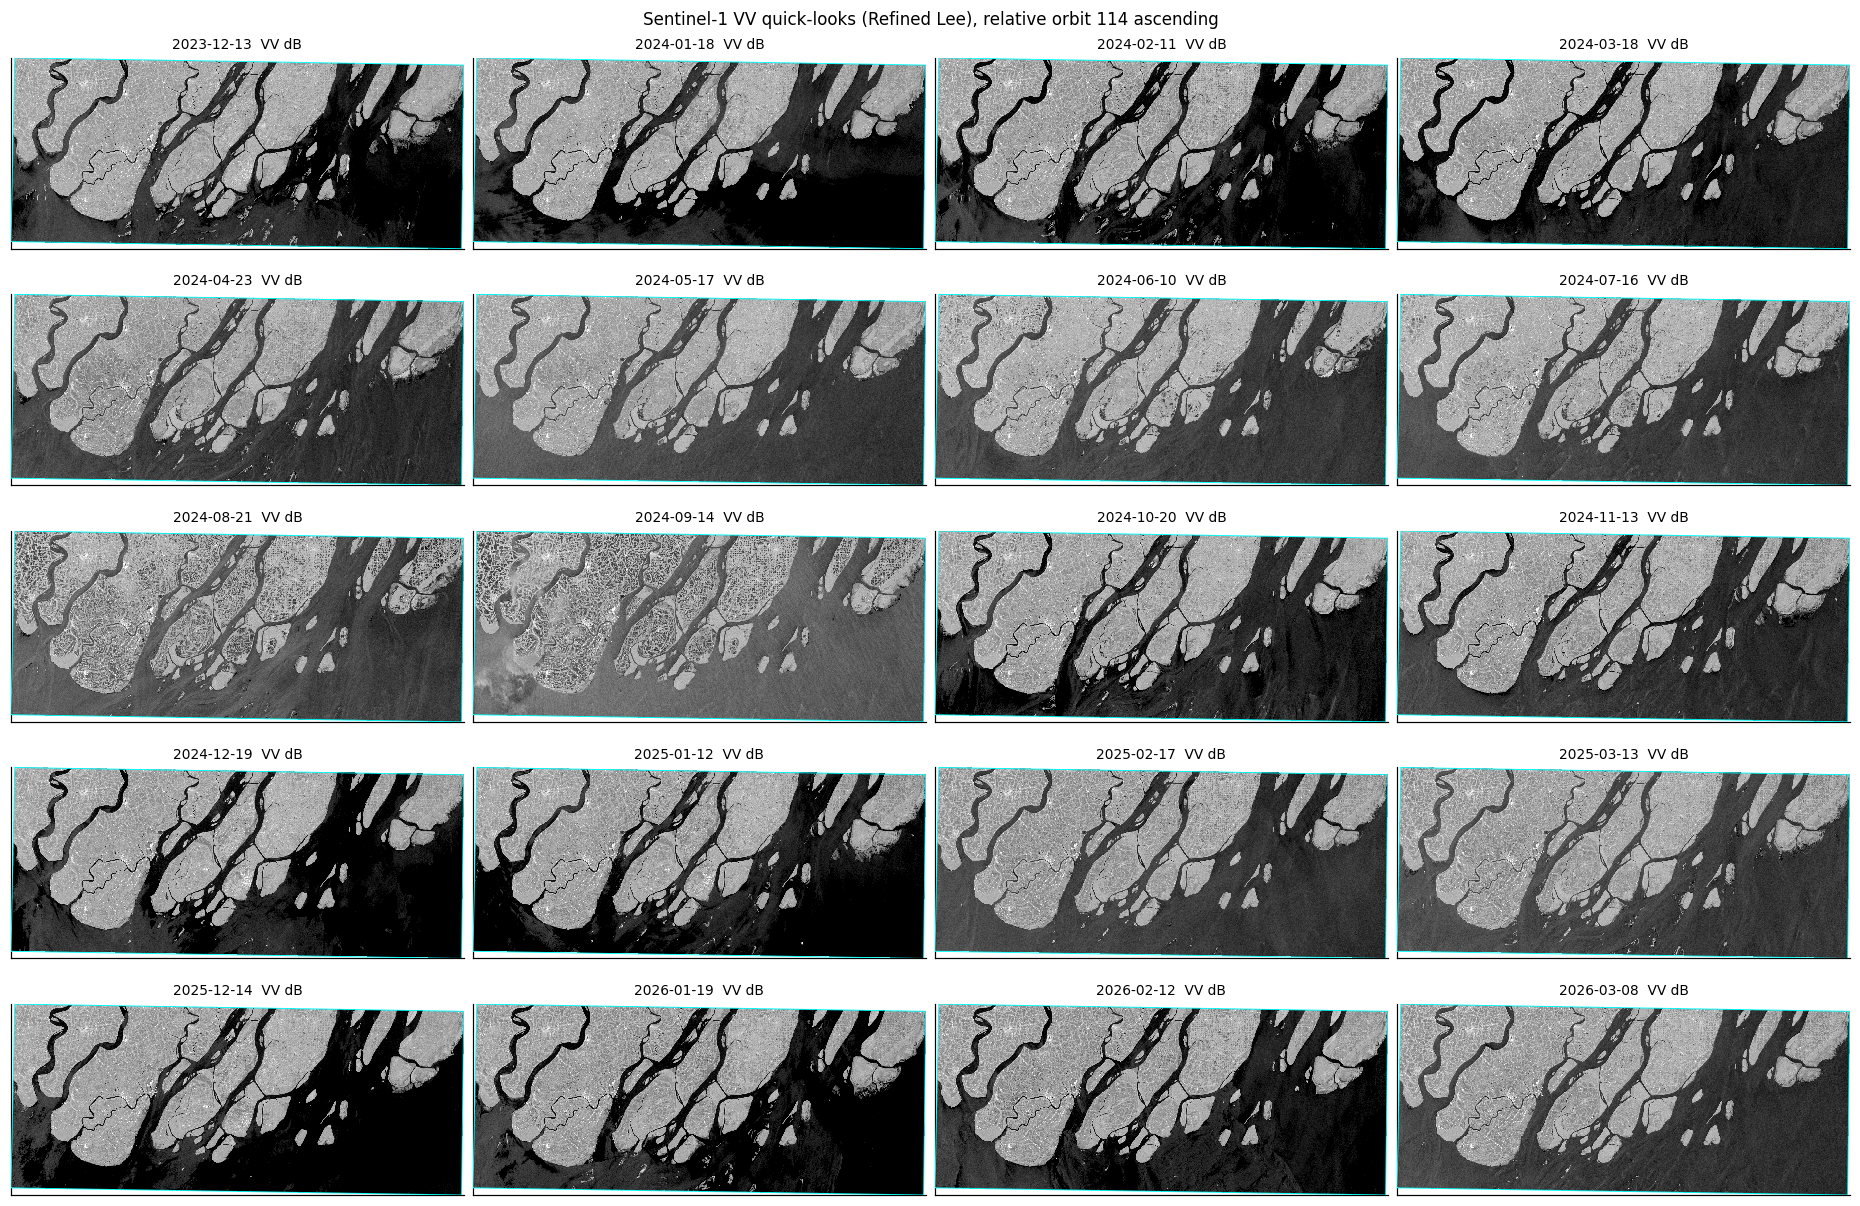

In [ ]:
# VV quick-looks for every scene (from the GeoTIFF overviews, so this is fast).
n = len(selected)
ncol = 4
nrow = int(math.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 2.2 * nrow), constrained_layout=True)
for ax, (_, scene) in zip(np.ravel(axes), selected.iterrows()):
    vv = read_band(OUT["preprocessed"] / f"sigma0_{scene.tag}.tif", 1, step=DISPLAY_STEP)
    show_map(ax, vv, vmin=-25, vmax=0, title=f"{scene.date:%Y-%m-%d}  VV dB", step=1)
for ax in np.ravel(axes)[n:]:
    ax.axis("off")
fig.suptitle("Sentinel-1 VV quick-looks (Refined Lee), relative orbit "
             f"{MAIN_ORBIT} {MAIN_PASS.lower()}", fontsize=11)
savefig(fig, "quicklooks")
plt.show()

In [ ]:
# Coregistration drift against the master scene on two stable shoreline windows.

#    A straight shoreline only constrains the shift across it (an east-west coast fixes dy, not
#    dx), so three more windows with the densest land-water edges in two directions are added
#    automatically, and the drift of a scene is the median offset over all reliable windows.
DRIFT_WINDOWS = {"Kuakata shoreline": (90.12, 21.82), "Bhola south (Char Fasson)": (90.70, 22.17)}
WIN = max(64, int(round(5120 / RESOLUTION_M)))     # 5.1 km window (at least 64 px)
MIN_CORR = 0.3                                      # windows with weaker correlation are ignored

dry_scenes = selected[selected.season == "dry"]
MASTER_TAG = (dry_scenes if len(dry_scenes) else selected).iloc[0].tag
master_vv = read_band(OUT["preprocessed"] / f"sigma0_{MASTER_TAG}.tif", 1)

def window_slices(lon, lat):
    from pyproj import Transformer
    x, y = Transformer.from_crs(4326, GRID_CRS, always_xy=True).transform(lon, lat)
    col, row = ~GRID_TRANSFORM * (x, y)
    r0 = int(np.clip(row - WIN // 2, 0, max(0, GRID_H - WIN)))
    c0 = int(np.clip(col - WIN // 2, 0, max(0, GRID_W - WIN)))
    return slice(r0, r0 + WIN), slice(c0, c0 + WIN)

def edge_windows(img, k=3):
    # Blocks of size WIN whose x- and y-gradients are both strong (edges in two directions).
    z = np.nan_to_num(img, nan=np.nanmedian(img))
    gy, gx = np.abs(np.diff(z, axis=0))[:, :-1], np.abs(np.diff(z, axis=1))[:-1, :]
    nb_r, nb_c = (GRID_H - 1) // WIN, (GRID_W - 1) // WIN
    score = []
    for i in range(nb_r):
        for j in range(nb_c):
            s_ = (slice(i * WIN, (i + 1) * WIN), slice(j * WIN, (j + 1) * WIN))
            if aoi_inside[s_].mean() < 0.9:
                continue
            score.append((min(gx[s_].mean(), gy[s_].mean()), s_))
    score.sort(key=lambda t: -t[0])
    return {f"auto edge window {n + 1}": s_ for n, (_, s_) in enumerate(score[:k])}

windows = {name: window_slices(lon, lat) for name, (lon, lat) in DRIFT_WINDOWS.items()}
windows.update(edge_windows(master_vv))

drift_rows = []
for _, scene in selected.iterrows():
    vv = master_vv if scene.tag == MASTER_TAG else read_band(OUT["preprocessed"] / f"sigma0_{scene.tag}.tif", 1)
    rec, offs = {"tag": scene.tag}, []
    for name, (rs_, cs_) in windows.items():
        ref, mov = master_vv[rs_, cs_], vv[rs_, cs_]
        if np.isfinite(ref).mean() < 0.5 or np.isfinite(mov).mean() < 0.5:
            rec[name] = "no data"
            continue
        dy, dx, corr = rs.sar.estimate_offset(mov, ref, max_shift=5, smooth=3)
        rec[name] = f"dy={dy:+d} dx={dx:+d} (r={corr:.2f})"
        if corr >= MIN_CORR:
            offs.append((dy, dx))
    if offs:
        mdy, mdx = np.median(np.array(offs), axis=0)
        rec["drift_dy_px"], rec["drift_dx_px"] = float(mdy), float(mdx)
        rec["max_drift_px"] = float(max(abs(mdy), abs(mdx)))
    else:
        rec["drift_dy_px"] = rec["drift_dx_px"] = rec["max_drift_px"] = np.nan
    drift_rows.append(rec)
    del vv
drift = pd.DataFrame(drift_rows)
selected = selected.merge(drift[["tag", "max_drift_px"]], on="tag", how="left")
display(drift)
print(f"Master: {MASTER_TAG}. Drift = median offset over windows with r >= {MIN_CORR}. "
      f"Scenes with drift > {MAX_DRIFT_PX:g} px: {int((selected.max_drift_px > MAX_DRIFT_PX).sum())}")

,tag,Kuakata shoreline,Bhola south (Char Fasson),auto edge window 1,auto edge window 2,auto edge window 3,drift_dy_px,drift_dx_px,max_drift_px
0,20231213,dy=+0 dx=+0 (r=1.00),dy=+0 dx=+0 (r=0.95),dy=+0 dx=+0 (r=0.94),dy=+0 dx=+0 (r=0.93),dy=+0 dx=+0 (r=0.95),0.0,0.0,0.0
1,20240118,dy=+0 dx=+0 (r=0.96),dy=+0 dx=+0 (r=0.45),dy=-1 dx=+2 (r=0.06),dy=+2 dx=+3 (r=0.08),dy=+1 dx=+1 (r=0.07),0.0,0.0,0.0
2,20240211,dy=+0 dx=+0 (r=0.96),dy=+0 dx=-1 (r=0.48),dy=+0 dx=-2 (r=-0.08),dy=-5 dx=-5 (r=-0.05),dy=-3 dx=-2 (r=0.03),0.0,-0.5,0.5
3,20240318,dy=+0 dx=+0 (r=0.95),dy=+0 dx=+0 (r=0.53),dy=+3 dx=-1 (r=0.04),dy=+5 dx=+5 (r=0.02),dy=+5 dx=-3 (r=0.01),0.0,0.0,0.0
4,20240423,dy=+0 dx=+0 (r=0.94),dy=+0 dx=+0 (r=0.47),dy=-5 dx=+5 (r=0.00),dy=+5 dx=+0 (r=0.05),dy=+2 dx=-2 (r=0.23),0.0,0.0,0.0
5,20240517,dy=+0 dx=+0 (r=0.94),dy=+0 dx=+0 (r=0.30),dy=+5 dx=+5 (r=0.05),dy=+5 dx=-2 (r=0.01),dy=-5 dx=-4 (r=0.08),0.0,0.0,0.0
6,20240610,dy=+0 dx=+0 (r=0.95),dy=+0 dx=+0 (r=0.44),dy=+2 dx=-5 (r=0.05),dy=-1 dx=-5 (r=0.03),dy=-5 dx=+5 (r=0.02),0.0,0.0,0.0
7,20240716,dy=+0 dx=+0 (r=0.94),dy=+0 dx=+0 (r=0.38),dy=+5 dx=-5 (r=-0.00),dy=-5 dx=-5 (r=0.02),dy=+5 dx=-5 (r=0.04),0.0,0.0,0.0
8,20240821,dy=+0 dx=+0 (r=0.80),dy=+0 dx=-1 (r=0.41),dy=-1 dx=+4 (r=0.07),dy=-2 dx=-3 (r=0.05),dy=+3 dx=-2 (r=0.07),0.0,-0.5,0.5
9,20240914,dy=-1 dx=+0 (r=0.57),dy=+0 dx=-1 (r=0.45),dy=-5 dx=+4 (r=0.02),dy=-4 dx=+1 (r=0.04),dy=-5 dx=+4 (r=0.02),-0.5,-0.5,0.5


Master: 20231213. Drift = median offset over windows with r >= 0.3. Scenes with drift > 1 px: 0


## Per-scene land/water classification

Each scene gets its own threshold (protocol):

1. **Primary band VV.** The scene is cut into 2.56 km tiles. Tiles whose histogram is clearly bimodal are kept: each class holds 10 to 90% of the tile and the class means differ by at least 3 dB (the bimodality test of Martinis et al. 2015). An Otsu (or Kittler-Illingworth) threshold is fitted on each kept tile and the **median** is the scene threshold.
2. **Wind check with VH.** If the water pixels have a median VV brighter than −15 dB, the water surface is wind-roughened; the scene is then thresholded on VH, which is less sensitive to wind.
3. **Wet mudflats.** Pixels within 2 dB of the threshold are labelled *uncertain* (code 2) instead of being forced into a class.
4. **Cleaning.** Land objects smaller than 0.5 ha are removed and water holes smaller than 0.5 ha inside land are filled.

Output: `classified/water_YYYYMMDD.tif` with 0 water, 1 land, 2 uncertain, 255 NoData.


In [ ]:
# Tile-based thresholds and the per-scene classifier.

def threshold_ki(values, nbins=256):
    # Kittler-Illingworth minimum-error threshold on a 1-D sample.
    hist, edges = np.histogram(values, bins=nbins)
    c = (edges[:-1] + edges[1:]) / 2
    p = hist / hist.sum()
    P1 = np.cumsum(p); P2 = 1 - P1
    with np.errstate(divide="ignore", invalid="ignore"):
        m1 = np.cumsum(p * c) / P1
        m2 = (np.sum(p * c) - np.cumsum(p * c)) / P2
        v1 = np.cumsum(p * c**2) / P1 - m1**2
        v2 = (np.sum(p * c**2) - np.cumsum(p * c**2)) / P2 - m2**2
        J = 1 + 2 * (P1 * np.log(np.sqrt(v1)) + P2 * np.log(np.sqrt(v2))) \
              - 2 * (P1 * np.log(P1) + P2 * np.log(P2))
    J[~np.isfinite(J)] = np.inf
    return float(c[int(np.argmin(J))])

def tile_threshold(db, valid, tile=None, method=None):
    # Median threshold over tiles that hold both water and land (protocol, Martinis et al. 2015).
    tile = tile or TILE_PX
    method = method or THRESHOLD_METHOD
    ths = []
    H, W = db.shape
    for i in range(0, H, tile):
        for j in range(0, W, tile):
            m = valid[i:i + tile, j:j + tile]
            if m.sum() < tile * tile * 0.5:
                continue
            t = db[i:i + tile, j:j + tile][m]
            if np.ptp(t) < TILE_MIN_SEP_DB:
                continue
            th = threshold_otsu(t) if method == "otsu" else threshold_ki(t)
            lo, hi = t[t < th], t[t >= th]
            frac = lo.size / t.size
            if TILE_MIN_FRAC < frac < 1 - TILE_MIN_FRAC and hi.mean() - lo.mean() >= TILE_MIN_SEP_DB:
                ths.append(float(th))
    if not ths:
        return DEFAULT_THRESHOLD_DB, 0, ths
    return float(np.median(ths)), len(ths), ths

def classify_db(base_db, valid, th):
    # Water (0) / land (1) / uncertain (2) / NoData (255) from one dB image and its threshold.
    out = np.full(base_db.shape, 255, np.uint8)
    land = valid & (base_db >= th)
    land = remove_small(land, MIN_OBJECT_PX)                 # drop land specks < 0.5 ha
    land = fill_small_holes(land, MIN_OBJECT_PX) & valid     # fill water holes < 0.5 ha
    out[valid] = 0
    out[land] = 1
    out[valid & (np.abs(base_db - th) < UNCERTAIN_BAND_DB)] = 2
    return out

def classify_scene(vv_db, vh_db):
    valid = np.isfinite(vv_db) & np.isfinite(vh_db) & aoi_inside
    th_vv, n_vv, ths_vv = tile_threshold(vv_db, valid)
    water = valid & (vv_db < th_vv)
    water_vv = float(np.nanmedian(vv_db[water])) if water.any() else np.nan
    band, base, th, n_tiles, ths = "VV", vv_db, th_vv, n_vv, ths_vv
    if np.isfinite(water_vv) and water_vv > ROUGH_WATER_VV_DB:
        th_vh, n_vh, ths_vh = tile_threshold(vh_db, valid)
        if n_vh > 0:
            band, base, th, n_tiles, ths = "VH", vh_db, th_vh, n_vh, ths_vh
    out = classify_db(base, valid, th)
    stats = {"band": band, "threshold_db": round(th, 2), "n_tiles": n_tiles,
             "water_vv_median_db": round(water_vv, 2) if np.isfinite(water_vv) else np.nan,
             "water_frac": float((out == 0).sum() / max(1, valid.sum())),
             "land_frac": float((out == 1).sum() / max(1, valid.sum())),
             "uncertain_frac": float((out == 2).sum() / max(1, valid.sum()))}
    return out, stats, ths
print("Classifier ready.")

Classifier ready.


In [ ]:
# Classify every selected scene and record the fitted thresholds.

class_stats, tile_ths = [], {}
for _, scene in selected.iterrows():
    path = OUT["classified"] / f"water_{scene.tag}.tif"
    stats_path = OUT["classified"] / f"water_{scene.tag}.json"
    if path.exists() and stats_path.exists() and not OVERWRITE:
        stats = json.loads(stats_path.read_text())
    else:
        sig = OUT["preprocessed"] / f"sigma0_{scene.tag}.tif"
        vv_db, vh_db = read_band(sig, 1), read_band(sig, 2)
        out, stats, ths = classify_scene(vv_db, vh_db)
        write_raster(path, out, dtype="uint8", nodata=255, names=["water0_land1_uncertain2"])
        stats_path.write_text(json.dumps(stats))
        tile_ths[scene.tag] = ths
        del vv_db, vh_db, out
    class_stats.append({"tag": scene.tag, **stats})
    print(f"{scene.tag}: {stats['band']} threshold {stats['threshold_db']:.2f} dB from "
          f"{stats['n_tiles']} tiles | water {stats['water_frac']:.1%} land {stats['land_frac']:.1%} "
          f"uncertain {stats['uncertain_frac']:.1%}")
class_stats = pd.DataFrame(class_stats)
selected = selected.drop(columns=[c for c in class_stats.columns if c != "tag" and c in selected],
                         errors="ignore").merge(class_stats, on="tag", how="left")
if (selected.n_tiles == 0).any():
    print("Warning: default threshold used for", list(selected.loc[selected.n_tiles == 0, "tag"]))

20231213: VV threshold -15.76 dB from 594 tiles | water 48.8% land 47.5% uncertain 3.7%
20240118: VV threshold -16.00 dB from 653 tiles | water 53.0% land 45.6% uncertain 1.5%
20240211: VV threshold -16.43 dB from 827 tiles | water 49.9% land 47.2% uncertain 2.9%
20240318: VV threshold -15.56 dB from 529 tiles | water 53.0% land 46.0% uncertain 1.0%
20240423: VV threshold -12.99 dB from 514 tiles | water 52.6% land 38.2% uncertain 9.2%
20240517: VV threshold -12.71 dB from 397 tiles | water 52.4% land 40.8% uncertain 6.8%
20240610: VV threshold -12.47 dB from 439 tiles | water 55.0% land 40.4% uncertain 4.6%
20240716: VV threshold -12.72 dB from 440 tiles | water 54.6% land 41.1% uncertain 4.3%
20240821: VV threshold -11.75 dB from 611 tiles | water 60.0% land 27.5% uncertain 12.5%
20240914: VV threshold -11.70 dB from 604 tiles | water 54.4% land 25.7% uncertain 20.0%
20241020: VV threshold -14.81 dB from 594 tiles | water 52.7% land 45.3% uncertain 2.0%
20241113: VV threshold -13.94 

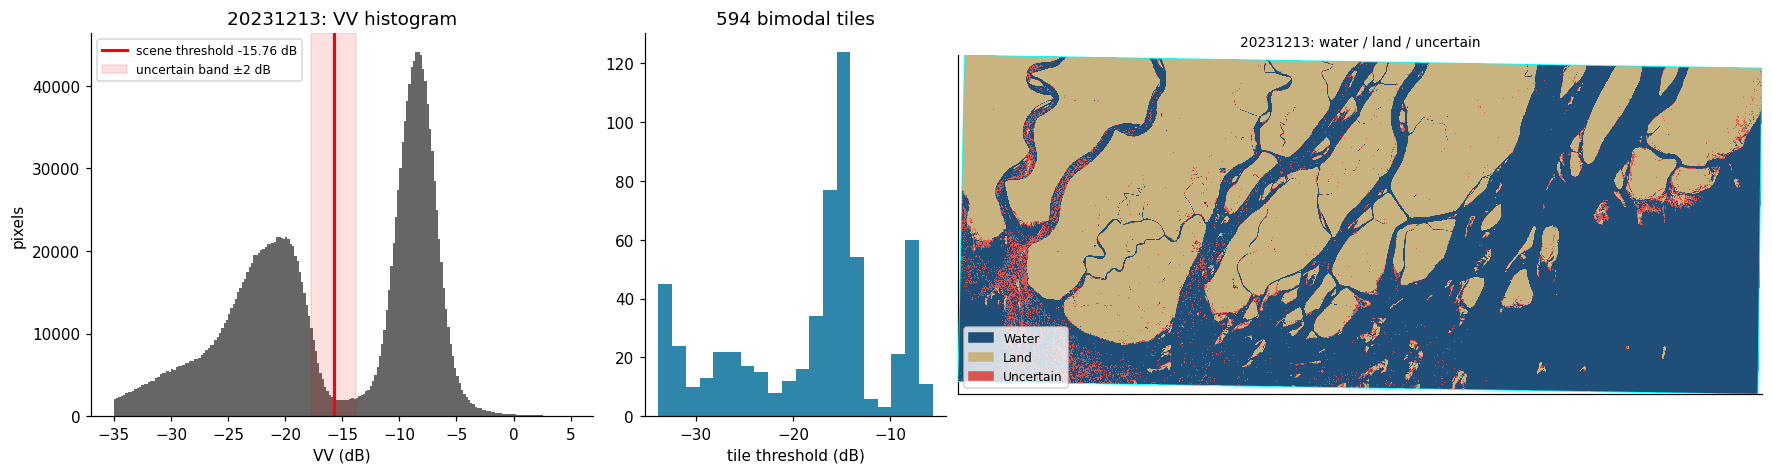

In [ ]:
# Threshold diagnostics for the master scene: VV histogram, tile thresholds and the classified map.
sig = OUT["preprocessed"] / f"sigma0_{MASTER_TAG}.tif"
vv_db = read_band(sig, 1)
row = selected.set_index("tag").loc[MASTER_TAG]
ths = tile_ths.get(MASTER_TAG) or tile_threshold(vv_db, np.isfinite(vv_db) & aoi_inside)[2]
sample = vv_db[np.isfinite(vv_db)]
sample = RNG.choice(sample, size=min(sample.size, 2_000_000), replace=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 0.6, 1.6]},
                         constrained_layout=True)
axes[0].hist(sample, bins=200, range=(-35, 5), color="0.4")
axes[0].axvline(row.threshold_db, color="red", lw=2, label=f"scene threshold {row.threshold_db:.2f} dB")
axes[0].axvspan(row.threshold_db - UNCERTAIN_BAND_DB, row.threshold_db + UNCERTAIN_BAND_DB,
                color="red", alpha=0.12, label="uncertain band ±2 dB")
axes[0].set_xlabel("VV (dB)"); axes[0].set_ylabel("pixels"); axes[0].legend(fontsize=8)
axes[0].set_title(f"{MASTER_TAG}: VV histogram")
axes[1].hist(ths, bins=20, color="#2E86AB")
axes[1].set_xlabel("tile threshold (dB)"); axes[1].set_title(f"{len(ths)} bimodal tiles")
water = read_band(OUT["classified"] / f"water_{MASTER_TAG}.tif", 1, step=DISPLAY_STEP)
cmap, norm = categorical(3, WATER_COLORS)
show_map(axes[2], masked_codes(water), cmap=cmap, norm=norm, step=1,
         title=f"{MASTER_TAG}: water / land / uncertain")
axes[2].legend(handles=[Patch(color=c, label=WATER_NAMES[i]) for i, c in enumerate(WATER_COLORS)],
               loc="lower left", fontsize=8)
savefig(fig, "threshold_master")
plt.show()
del vv_db, sample

### Optional: resolve uncertain pixels with a Random Forest

The protocol allows a Random Forest on VV, VH, VH/VV, texture and the temporal median and standard deviation where thresholds fail repeatedly. Its labels should come from Sentinel-2 MNDWI within 3 days of each scene; no Sentinel-2 scenes are in the folder, so with `RESOLVE_UNCERTAIN = "rf"` this cell trains on each scene's own **confident** SAR pixels (codes 0 and 1) instead, and predicts the uncertain ones. This is self-training, not independent labelling, so keep the default `"exclude"` (uncertain pixels drop out of the land-frequency denominator) unless you have checked the result.


In [ ]:
# Optional Random Forest resolution of uncertain pixels (runs only if RESOLVE_UNCERTAIN == "rf").
if RESOLVE_UNCERTAIN == "rf":
    from sklearn.ensemble import RandomForestClassifier
    # 1. Temporal mean and standard deviation of VV dB across all selected scenes (streamed).
    s1 = np.zeros((GRID_H, GRID_W), "float64"); s2 = np.zeros_like(s1); cnt = np.zeros(s1.shape, "uint16")
    for tag in selected.tag:
        v = read_band(OUT["preprocessed"] / f"sigma0_{tag}.tif", 1)
        ok = np.isfinite(v); s1[ok] += v[ok]; s2[ok] += v[ok] ** 2; cnt += ok
    with np.errstate(invalid="ignore", divide="ignore"):
        t_mean = (s1 / cnt).astype("float32"); t_std = np.sqrt(np.maximum(s2 / cnt - t_mean**2, 0)).astype("float32")
    del s1, s2
    for tag in selected.tag:
        path = OUT["classified"] / f"water_{tag}.tif"
        cls = read_band(path, 1)
        unc = cls == 2
        if not unc.any():
            continue
        sig = OUT["preprocessed"] / f"sigma0_{tag}.tif"
        vv, vh, ratio = read_band(sig, 1), read_band(sig, 2), read_band(sig, 3)
        # 2. Local texture: 5x5 standard deviation of VV dB.
        vv0 = np.nan_to_num(vv, nan=np.nanmedian(vv))
        tex = np.sqrt(np.maximum(ndi.uniform_filter(vv0**2, 5) - ndi.uniform_filter(vv0, 5) ** 2, 0)).astype("float32")
        feats = [vv, vh, rs.sar.to_db(ratio), tex, t_mean, t_std]
        # 3. Balanced training sample of confident pixels from this scene.
        idx = []
        for c in (0, 1):
            pool = np.flatnonzero((cls == c).ravel())
            idx.append(RNG.choice(pool, size=min(pool.size, 30000), replace=False))
        idx = np.concatenate(idx)
        X = np.column_stack([f.ravel()[idx] for f in feats]); y = cls.ravel()[idx]
        ok = np.isfinite(X).all(1)
        rf = RandomForestClassifier(n_estimators=150, max_depth=16, n_jobs=-1, random_state=42).fit(X[ok], y[ok])
        # 4. Predict the uncertain pixels and rewrite the scene map.
        u = np.flatnonzero(unc.ravel())
        Xu = np.column_stack([f.ravel()[u] for f in feats]); good = np.isfinite(Xu).all(1)
        flat = cls.ravel().copy(); flat[u[good]] = rf.predict(Xu[good])
        write_raster(path, flat.reshape(cls.shape), dtype="uint8", nodata=255, names=["water0_land1_uncertain2"])
        print(f"{tag}: resolved {good.sum():,} of {u.size:,} uncertain pixels")
    del t_mean, t_std
else:
    print("RESOLVE_UNCERTAIN = 'exclude': uncertain pixels are left out of land frequency (protocol skeleton).")

RESOLVE_UNCERTAIN = 'exclude': uncertain pixels are left out of land frequency (protocol skeleton).


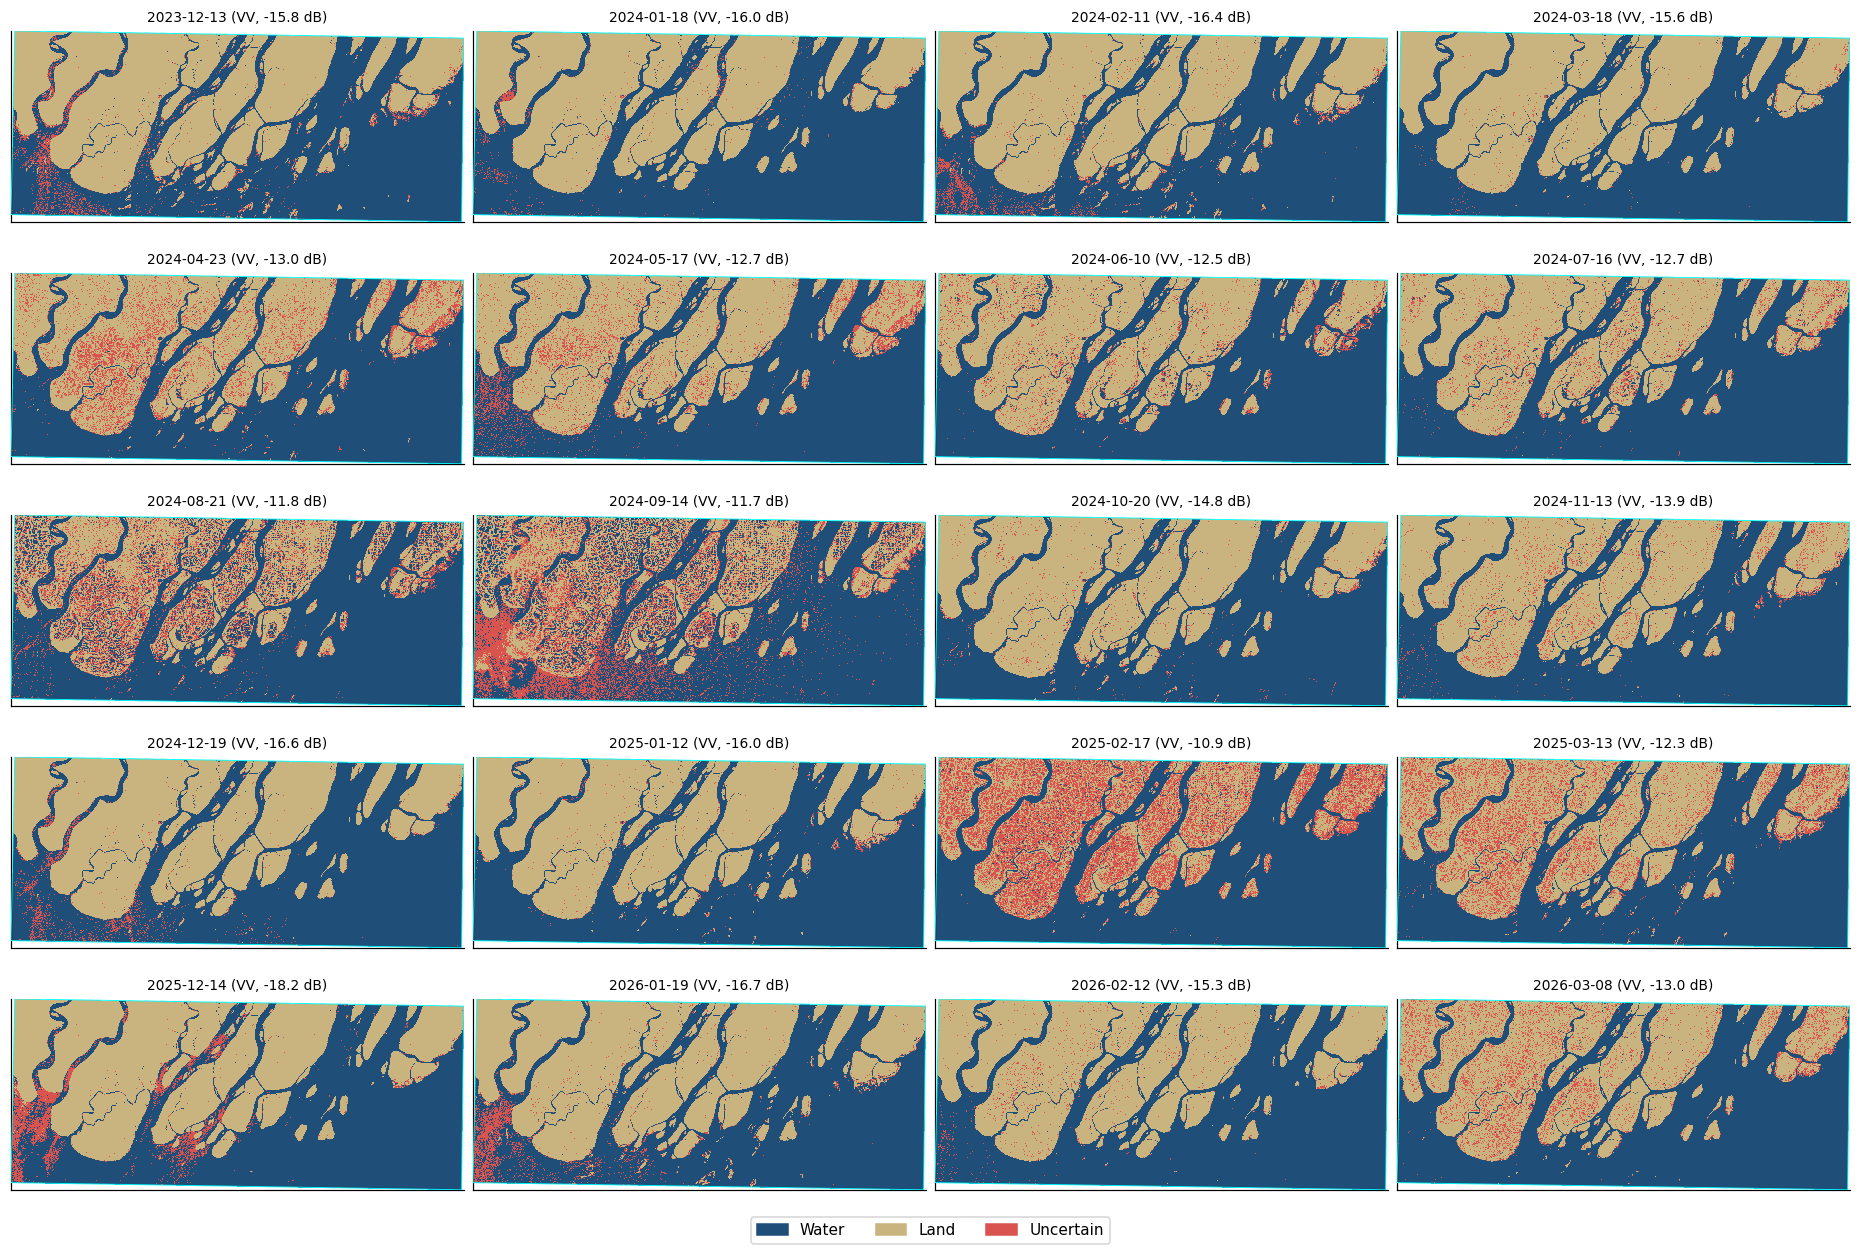

In [ ]:
# Small multiples of all classified scenes.
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 2.2 * nrow), constrained_layout=True)
cmap, norm = categorical(3, WATER_COLORS)
for ax, (_, scene) in zip(np.ravel(axes), selected.iterrows()):
    w = read_band(OUT["classified"] / f"water_{scene.tag}.tif", 1, step=DISPLAY_STEP)
    show_map(ax, masked_codes(w), cmap=cmap, norm=norm, step=1,
             title=f"{scene.date:%Y-%m-%d} ({scene.band}, {scene.threshold_db:.1f} dB)")
for ax in np.ravel(axes)[n:]:
    ax.axis("off")
fig.legend(handles=[Patch(color=c, label=WATER_NAMES[i]) for i, c in enumerate(WATER_COLORS)],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.03))
savefig(fig, "classified_scenes")
plt.show()

## Tide and wind tagging, scene flags and the scene catalog

**Tide.** A pixel that is land at low tide and water at high tide is intertidal, not changing, so every scene needs a tide value. The notebook takes the first source available:

1. `scene_tide.csv` (gauge or other observed tide, metres above MSL);
2. `pyTMD` with the FES/TPXO model in `PYTMD_MODEL_DIR`, evaluated at an open-water point on the AOI's south edge at the scene's UTC time;
3. a **SAR water-level index**: the share of the intertidal zone (pixels that are land in 10 to 90% of all scenes) that is water in the scene, as a z-score. It ranks scenes from low to high water and is used only for tide terciles. It mixes tide with river stage, which matters most in the monsoon, and it has no unit.

**Wind.** ERA5 10 m wind from `era5_wind.csv` when present (flag above 7 m/s). Otherwise the proxy is the median VV of the deep permanent-water core (open estuary at least 500 m from any land): above −15 dB the water is wind-roughened and the scene is flagged.

Flagged scenes (wind, cyclone, drift, RFI) stay in the archive and catalog but are excluded from composites and land frequency.


In [ ]:
# Land frequency over all selected scenes: defines the intertidal zone and the open-water core.

def land_frequency(tags):
    # Stream classified scenes: land count / valid count per pixel (uncertain pixels excluded).
    land = np.zeros((GRID_H, GRID_W), np.uint16)
    valid = np.zeros((GRID_H, GRID_W), np.uint16)
    for tag in tags:
        c = read_band(OUT["classified"] / f"water_{tag}.tif", 1)
        land += c == 1
        valid += (c == 0) | (c == 1)
    with np.errstate(invalid="ignore", divide="ignore"):
        freq = np.where(valid > 0, land / valid, np.nan).astype("float32")
    return freq, valid

def frequency_classes(freq):
    cls = np.full(freq.shape, 255, np.uint8)
    ok = np.isfinite(freq)
    cls[ok & (freq < FREQ_WATER)] = 0
    cls[ok & (freq >= FREQ_WATER) & (freq < FREQ_LAND)] = 1
    cls[ok & (freq >= FREQ_LAND)] = 2
    return cls

freq_all, nvalid_all = land_frequency(selected.tag)
intertidal_zone = (freq_all >= FREQ_WATER) & (freq_all < FREQ_LAND)
# Open-water core: permanent water eroded by 500 m (box erosion via a moving average).
r = int(round(500 / RESOLUTION_M))
perm_water = (freq_all < FREQ_WATER) & np.isfinite(freq_all)
water_core = ndi.uniform_filter(perm_water.astype("float32"), size=2 * r + 1) > 0.999
print(f"Intertidal zone (all scenes): {intertidal_zone.sum() * PIXEL_KM2:,.1f} km² | "
      f"open-water core: {water_core.sum() * PIXEL_KM2:,.1f} km²")

Intertidal zone (all scenes): 600.7 km² | open-water core: 2,540.8 km²


In [ ]:
# Tide, wind and QA flags for every scene; write scene_catalog.csv.

def tide_from_pytmd(times_utc):
    # Modelled tide (m) at TIDE_POINT with pyTMD; returns None if pyTMD or the model is unavailable.
    if not TIDE_MODEL_DIR:
        return None
    try:
        import pyTMD
        lon, lat = TIDE_POINT
        n = len(times_utc)
        delta = (pd.to_datetime(times_utc) - pd.Timestamp("2000-01-01")).total_seconds().to_numpy()
        h = pyTMD.compute.tide_elevations(np.full(n, lon), np.full(n, lat), delta,
                                          DIRECTORY=TIDE_MODEL_DIR, MODEL=TIDE_MODEL, EPSG=4326,
                                          EPOCH=(2000, 1, 1, 0, 0, 0), TYPE="drift", TIME="UTC",
                                          EXTRAPOLATE=True)
        return np.asarray(h, dtype=float).ravel()
    except Exception as exc:                       # missing model files, API differences, etc.
        print("pyTMD tide prediction failed:", exc)
        return None

core_idx = np.flatnonzero(water_core.ravel())
core_idx = RNG.choice(core_idx, size=min(core_idx.size, 500_000), replace=False) if core_idx.size else core_idx
zone_n = max(1, int(intertidal_zone.sum()))
wl, wvv = [], []
for tag in selected.tag:
    c = read_band(OUT["classified"] / f"water_{tag}.tif", 1)
    z = intertidal_zone & ((c == 0) | (c == 1))
    wl.append((c[z] == 0).sum() / max(1, z.sum()))
    vv = read_band(OUT["preprocessed"] / f"sigma0_{tag}.tif", 1).ravel()
    wvv.append(float(np.nanmedian(vv[core_idx])) if core_idx.size else np.nan)
selected["water_level_frac"] = np.round(wl, 4)
selected["tide_index"] = np.round((selected.water_level_frac - selected.water_level_frac.mean())
                                  / (selected.water_level_frac.std(ddof=0) or 1), 3)
selected["open_water_vv_db"] = np.round(wvv, 2)

# Tide source priority: observed CSV, then pyTMD, then the SAR water-level index.
selected["tide_m"] = np.nan
if TIDE_CSV.exists():
    tide_obs = pd.read_csv(TIDE_CSV, parse_dates=["date"]).set_index("date")["tide_m"]
    selected["tide_m"] = selected.date.map(tide_obs)
    TIDE_SOURCE = f"observed ({TIDE_CSV.name})"
else:
    modelled = tide_from_pytmd(selected.time_utc)
    if modelled is not None:
        selected["tide_m"] = np.round(modelled, 3)
        TIDE_SOURCE = f"pyTMD {TIDE_MODEL}"
    else:
        TIDE_SOURCE = "SAR water-level index (proxy, unitless)"
TIDE_IN_METRES = selected.tide_m.notna().all()
selected["tide_rank_value"] = selected.tide_m if TIDE_IN_METRES else selected.tide_index

# Wind: ERA5 if available, else the open-water VV proxy.
selected["wind_ms"] = np.nan
if ERA5_CSV.exists():
    era5 = pd.read_csv(ERA5_CSV, parse_dates=["date"]).set_index("date")["wind_ms"]
    selected["wind_ms"] = selected.date.map(era5)
    WIND_SOURCE = f"ERA5 ({ERA5_CSV.name})"
    windy = selected.wind_ms > WIND_LIMIT_MS
else:
    WIND_SOURCE = "open-water VV proxy (> -15 dB = wind-roughened)"
    windy = selected.open_water_vv_db > ROUGH_WATER_VV_DB

# QA flags.
def flags_for(i, s):
    f = []
    if windy.iloc[i]: f.append("wind")
    if s.cyclone: f.append(f"cyclone:{s.cyclone}")
    if s.max_drift_px > MAX_DRIFT_PX: f.append("drift")
    if s.date.strftime("%Y-%m-%d") in RFI_REJECT: f.append("rfi")
    if s.n_tiles == 0: f.append("default_threshold")
    return ";".join(f) or "ok"
selected["qa_flag"] = [flags_for(i, s) for i, s in enumerate(selected.itertuples())]
selected["usable"] = ~selected.qa_flag.str.contains("wind|cyclone|drift|rfi")

catalog_out = selected[["date", "time_utc", "platform", "relative_orbit", "absolute_orbit", "pass",
                        "inc_min", "inc_max", "aoi_cover", "season", "dry_year", "tide_m", "tide_index",
                        "wind_ms", "open_water_vv_db", "band", "threshold_db", "n_tiles",
                        "water_frac", "land_frac", "uncertain_frac", "max_drift_px", "qa_flag", "usable"]]
catalog_out.rename(columns={"relative_orbit": "orbit"}).to_csv(DATA_DIR / "scene_catalog.csv", index=False)
print("Tide source:", TIDE_SOURCE, "| wind source:", WIND_SOURCE)
display(catalog_out)

Tide source: SAR water-level index (proxy, unitless) | wind source: open-water VV proxy (> -15 dB = wind-roughened)


,date,time_utc,platform,relative_orbit,absolute_orbit,pass,inc_min,inc_max,aoi_cover,season,...,open_water_vv_db,band,threshold_db,n_tiles,water_frac,land_frac,uncertain_frac,max_drift_px,qa_flag,usable
0,2023-12-13,2023-12-13 12:04:20,S1A,114,51636,ASCENDING,34.32,41.47,1.0,dry,...,-23.23,VV,-15.76,594,0.487859,0.475170,0.036972,0.0,ok,True
1,2024-01-18,2024-01-18 12:04:18,S1A,114,52161,ASCENDING,34.32,41.47,1.0,dry,...,-24.59,VV,-16.00,653,0.529711,0.455594,0.014695,0.0,ok,True
2,2024-02-11,2024-02-11 12:04:18,S1A,114,52511,ASCENDING,34.32,41.47,1.0,dry,...,-24.94,VV,-16.43,827,0.499063,0.471651,0.029286,0.5,ok,True
3,2024-03-18,2024-03-18 12:04:18,S1A,114,53036,ASCENDING,34.32,41.47,1.0,dry,...,-22.34,VV,-15.56,529,0.530389,0.459825,0.009786,0.0,ok,True
4,2024-04-23,2024-04-23 12:04:19,S1A,114,53561,ASCENDING,34.33,41.48,1.0,pre-monsoon,...,-19.91,VV,-12.99,514,0.526060,0.381675,0.092265,0.0,ok,True
5,2024-05-17,2024-05-17 12:04:19,S1A,114,53911,ASCENDING,34.32,41.48,1.0,pre-monsoon,...,-18.86,VV,-12.71,397,0.523638,0.408494,0.067868,0.0,ok,True
6,2024-06-10,2024-06-10 12:04:18,S1A,114,54261,ASCENDING,34.32,41.48,1.0,monsoon,...,-19.06,VV,-12.47,439,0.550042,0.404356,0.045601,0.0,ok,True
7,2024-07-16,2024-07-16 12:04:17,S1A,114,54786,ASCENDING,34.32,41.47,1.0,monsoon,...,-19.36,VV,-12.72,440,0.545889,0.411013,0.043098,0.0,ok,True
8,2024-08-21,2024-08-21 12:04:17,S1A,114,55311,ASCENDING,34.32,41.47,1.0,monsoon,...,-17.89,VV,-11.75,611,0.599636,0.275047,0.125316,0.5,ok,True
9,2024-09-14,2024-09-14 12:04:17,S1A,114,55661,ASCENDING,34.32,41.47,1.0,monsoon,...,-15.49,VV,-11.70,604,0.543546,0.256768,0.199686,0.5,ok,True


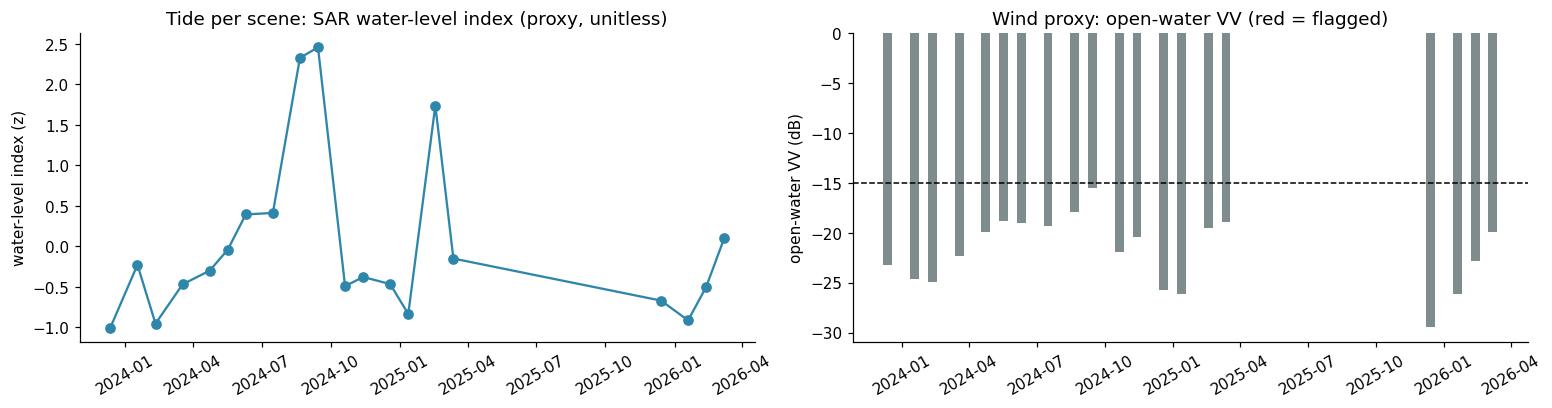

In [ ]:
# Tide / water-level and wind proxy through the year.
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), constrained_layout=True)
ycol = "tide_m" if TIDE_IN_METRES else "tide_index"
axes[0].plot(selected.date, selected[ycol], "o-", color="#2E86AB")
for s in selected.itertuples():
    if not s.usable:
        axes[0].plot(s.date, getattr(s, ycol), "x", color="red", ms=10)
axes[0].set_ylabel("tide (m)" if TIDE_IN_METRES else "water-level index (z)")
axes[0].set_title(f"Tide per scene: {TIDE_SOURCE}")
axes[1].bar(selected.date, selected.open_water_vv_db, width=12,
            color=np.where(windy, "#d9534f", "#7f8c8d"))
axes[1].axhline(ROUGH_WATER_VV_DB, color="k", ls="--", lw=1)
axes[1].set_ylabel("open-water VV (dB)"); axes[1].set_title("Wind proxy: open-water VV (red = flagged)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
savefig(fig, "tide_wind")
plt.show()

## Annual land frequency, tide-matched composites and class maps

Land frequency per pixel is (scenes classified land) ÷ (valid scenes), using only **usable** scenes. It is computed for these periods:

| Period | Scenes | Use |
|---|---|---|
| `dry_YYYY` (Dec–Mar, December counted with the next year) | dry-season scenes | reference season for annual comparison (protocol) |
| `monsoon_YYYY` (Jun–Oct) | monsoon scenes | descriptive only (protocol) |
| `nov_dec_YYYY` | November and December (only years with a November scene) | post-monsoon state, used for the within-year view of the monsoon |
| `year_YYYY` | every usable scene of a **full** calendar year (scenes in at least 10 months) | most robust single map, used for maturity |

With the current archive this gives `dry_2024`, `dry_2025`, `dry_2026`, `monsoon_2024`, `nov_dec_2024` and `year_2024`. The single December scenes of 2023 and 2025 belong to the dry seasons only; they do not make a `year_` or `nov_dec_` map.

Classes: permanent water (< 10%), intertidal (10–90%), stable land (≥ 90%).

**Tide-matched composites.** Within each dry season the scenes are split into low, mid and high terciles of tide. The **low-tide composite** (Quegan multi-temporal filter, then the temporal median of VV) shows the most land and is classified with the same tile threshold. A mid-tide composite is built the same way. These two composites provide the second line of evidence for the persistence rule in Step 8.


In [ ]:
# Land frequency and class maps for every period.

usable = selected[selected.usable].copy()
years = sorted(usable.date.dt.year.unique())
PERIODS = {}
for y in sorted(usable.dry_year.dropna().unique().astype(int)):
    PERIODS[f"dry_{y}"] = usable[(usable.season == "dry") & (usable.dry_year == y)]
for y in years:
    in_year = usable[usable.date.dt.year == y]
    PERIODS[f"monsoon_{y}"] = in_year[in_year.season == "monsoon"]
    # Post-monsoon map only when November was observed (a lone December scene is just dry season).
    if (in_year.date.dt.month == 11).any():
        PERIODS[f"nov_dec_{y}"] = in_year[in_year.date.dt.month.isin([11, 12])]
    # Calendar-year map only for (nearly) full years; partial years would be biased to their season.
    if in_year.date.dt.month.nunique() >= FULL_YEAR_MIN_MONTHS:
        PERIODS[f"year_{y}"] = in_year
PERIODS = {k: v for k, v in PERIODS.items() if len(v)}
PERIOD_MID = {k: v.date.mean() for k, v in PERIODS.items()}

CLASS_MAPS, period_rows = {}, []
for name, scenes in PERIODS.items():
    freq, nvalid = land_frequency(scenes.tag)
    freq[~aoi_inside] = np.nan
    cls = frequency_classes(freq)
    write_raster(OUT["annual"] / f"landfreq_{name}.tif", freq, dtype="float32", nodata=np.nan, names=["land_frequency"])
    write_raster(OUT["annual"] / f"class_{name}.tif", cls, dtype="uint8", nodata=255, names=["water0_intertidal1_stable2"])
    CLASS_MAPS[name] = cls
    areas = {CLASS_NAMES[c]: round(float((cls == c).sum() * PIXEL_KM2), 2) for c in CLASS_NAMES}
    period_rows.append({"period": name, "n_scenes": len(scenes),
                        "dates": ", ".join(scenes.date.dt.strftime("%m-%d")), **areas,
                        "complete": (not name.startswith("dry_")) or len(scenes) >= DRY_SEASON_MIN_SCENES})
    del freq, nvalid
period_table = pd.DataFrame(period_rows)
display(period_table)

,period,n_scenes,dates,Permanent water,Intertidal,Stable land,complete
0,dry_2024,4,"12-13, 01-18, 02-11, 03-18",3590.99,151.94,3200.40,True
1,dry_2025,4,"12-19, 01-12, 02-17, 03-13",3656.19,189.91,3104.30,True
2,dry_2026,4,"12-14, 01-19, 02-12, 03-08",3618.77,132.41,3198.91,True
3,monsoon_2024,5,"06-10, 07-16, 08-21, 09-14, 10-20",3692.55,903.39,2348.62,True
4,nov_dec_2024,2,"11-13, 12-19",3690.44,38.40,3203.22,True
5,year_2024,12,"01-18, 02-11, 03-18, 04-23, 05-17, 06-10, 07-1...",3645.00,622.60,2683.46,True


,period,n_scenes,dates,Permanent water,Intertidal,Stable land,land_km2,complete
0,dry_2024,4,"12-13, 01-18, 02-11, 03-18",3590.99,151.94,3200.40,3352.34,True
1,dry_2025,4,"12-19, 01-12, 02-17, 03-13",3656.19,189.91,3104.30,3294.21,True
2,dry_2026,4,"12-14, 01-19, 02-12, 03-08",3618.77,132.41,3198.91,3331.32,True


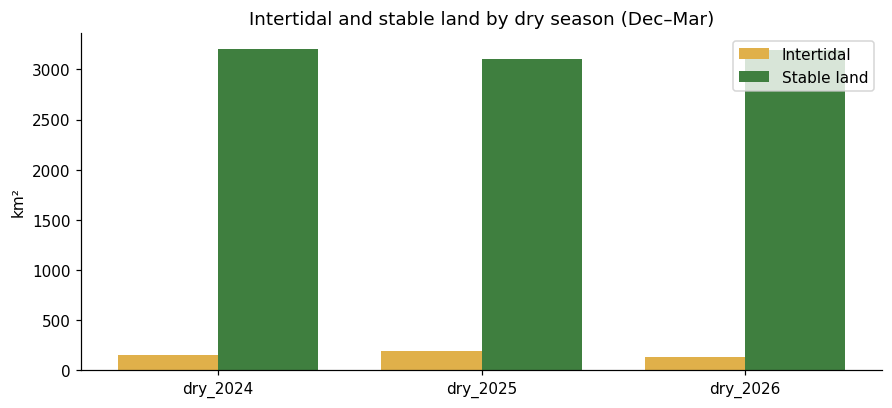

In [ ]:
# Class areas across the dry seasons (the reference season for year-to-year comparison).
dry_table = period_table[period_table.period.str.startswith("dry_")].copy()
dry_table["land_km2"] = dry_table["Intertidal"] + dry_table["Stable land"]
display(dry_table[["period", "n_scenes", "dates", "Permanent water", "Intertidal", "Stable land", "land_km2", "complete"]])

if len(dry_table) > 1:
    fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
    x = np.arange(len(dry_table))
    for k, (cname, color) in enumerate(zip(["Intertidal", "Stable land"], CLASS_COLORS[1:])):
        ax.bar(x + (k - 0.5) * 0.38, dry_table[cname], width=0.38, color=color, label=cname)
    ax.set_xticks(x, dry_table.period)
    ax.set_ylabel("km²"); ax.legend()
    ax.set_title("Intertidal and stable land by dry season (Dec–Mar)")
    savefig(fig, "dry_season_areas")
    plt.show()


In [ ]:
# Tide-matched (low / mid tide) dry-season composites.

def composite_vv(tags):
    # Quegan multi-temporal filter on the linear VV stack, then the temporal median, in dB.
    stack = np.stack([read_band(RAW_DIR / f"sigma0lin_{t}.tif", 1) for t in tags])
    if len(tags) > 1:
        filt = blockwise(lambda a: rs.sar.multitemporal_speckle_filter(a, spatial="refined_lee"), stack)
    else:
        filt = refined_lee_2d(stack[0])[None]
    del stack
    comp = np.nanmedian(filt, axis=0).astype("float32")
    return rs.sar.to_db(comp)

TIDE_BANDS, COMPOSITES = {}, {}
for name, scenes in PERIODS.items():
    if not name.startswith("dry_"):
        continue
    v = scenes.tide_rank_value.to_numpy(float)
    q1, q2 = np.quantile(v, [1 / 3, 2 / 3])
    bands = np.where(v <= q1, "low", np.where(v > q2, "high", "mid"))
    TIDE_BANDS[name] = dict(zip(scenes.tag, bands))
    year = name.split("_")[1]
    for band in ("low", "mid"):
        tags = [t for t, b in TIDE_BANDS[name].items() if b == band]
        if not tags:
            continue
        comp = composite_vv(tags)
        valid = np.isfinite(comp) & aoi_inside
        th, ntile, _ = tile_threshold(comp, valid)
        land = classify_db(comp, valid, th)
        write_raster(OUT["annual"] / f"{band}tide_comp_{year}.tif", comp, dtype="float32", nodata=np.nan,
                     names=[f"{band}_tide_VV_dB_median"])
        write_raster(OUT["annual"] / f"{band}tide_land_{year}.tif", land, dtype="uint8", nodata=255,
                     names=["water0_land1_uncertain2"])
        COMPOSITES[(name, band)] = {"tags": tags, "threshold": th, "land": land}
        print(f"{name} {band}-tide composite from {len(tags)} scene(s) {tags}: threshold {th:.2f} dB, "
              f"land {(land == 1).sum() * PIXEL_KM2:,.1f} km²")
        del comp
        if band == "low" and len(tags) < MIN_LOWTIDE_SCENES:
            print(f"  QA: low-tide composite has {len(tags)} scene(s) < {MIN_LOWTIDE_SCENES} required -> provisional")

dry_2024 low-tide composite from 2 scene(s) ['20231213', '20240211']: threshold -16.05 dB, land 3,245.9 km²
  QA: low-tide composite has 2 scene(s) < 5 required -> provisional
dry_2024 mid-tide composite from 1 scene(s) ['20240318']: threshold -15.56 dB, land 3,196.3 km²
dry_2025 low-tide composite from 2 scene(s) ['20241219', '20250112']: threshold -16.38 dB, land 3,196.2 km²
  QA: low-tide composite has 2 scene(s) < 5 required -> provisional
dry_2025 mid-tide composite from 1 scene(s) ['20250313']: threshold -12.29 dB, land 2,477.7 km²
dry_2026 low-tide composite from 2 scene(s) ['20251214', '20260119']: threshold -16.94 dB, land 3,230.8 km²
  QA: low-tide composite has 2 scene(s) < 5 required -> provisional
dry_2026 mid-tide composite from 1 scene(s) ['20260212']: threshold -15.34 dB, land 3,162.5 km²


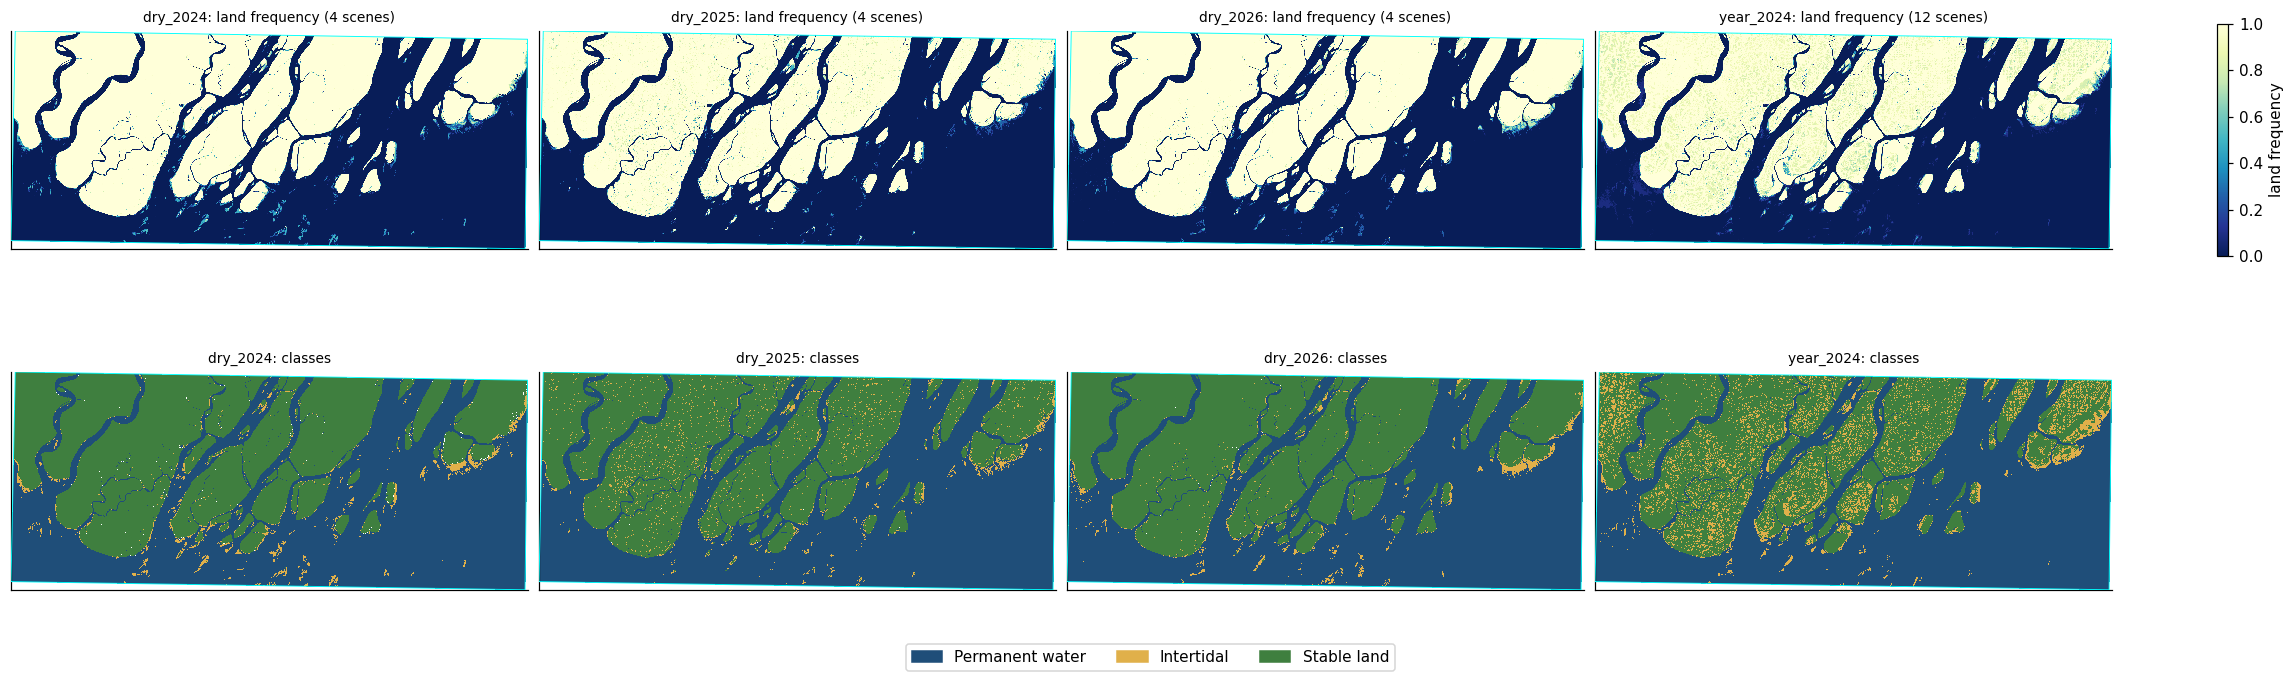

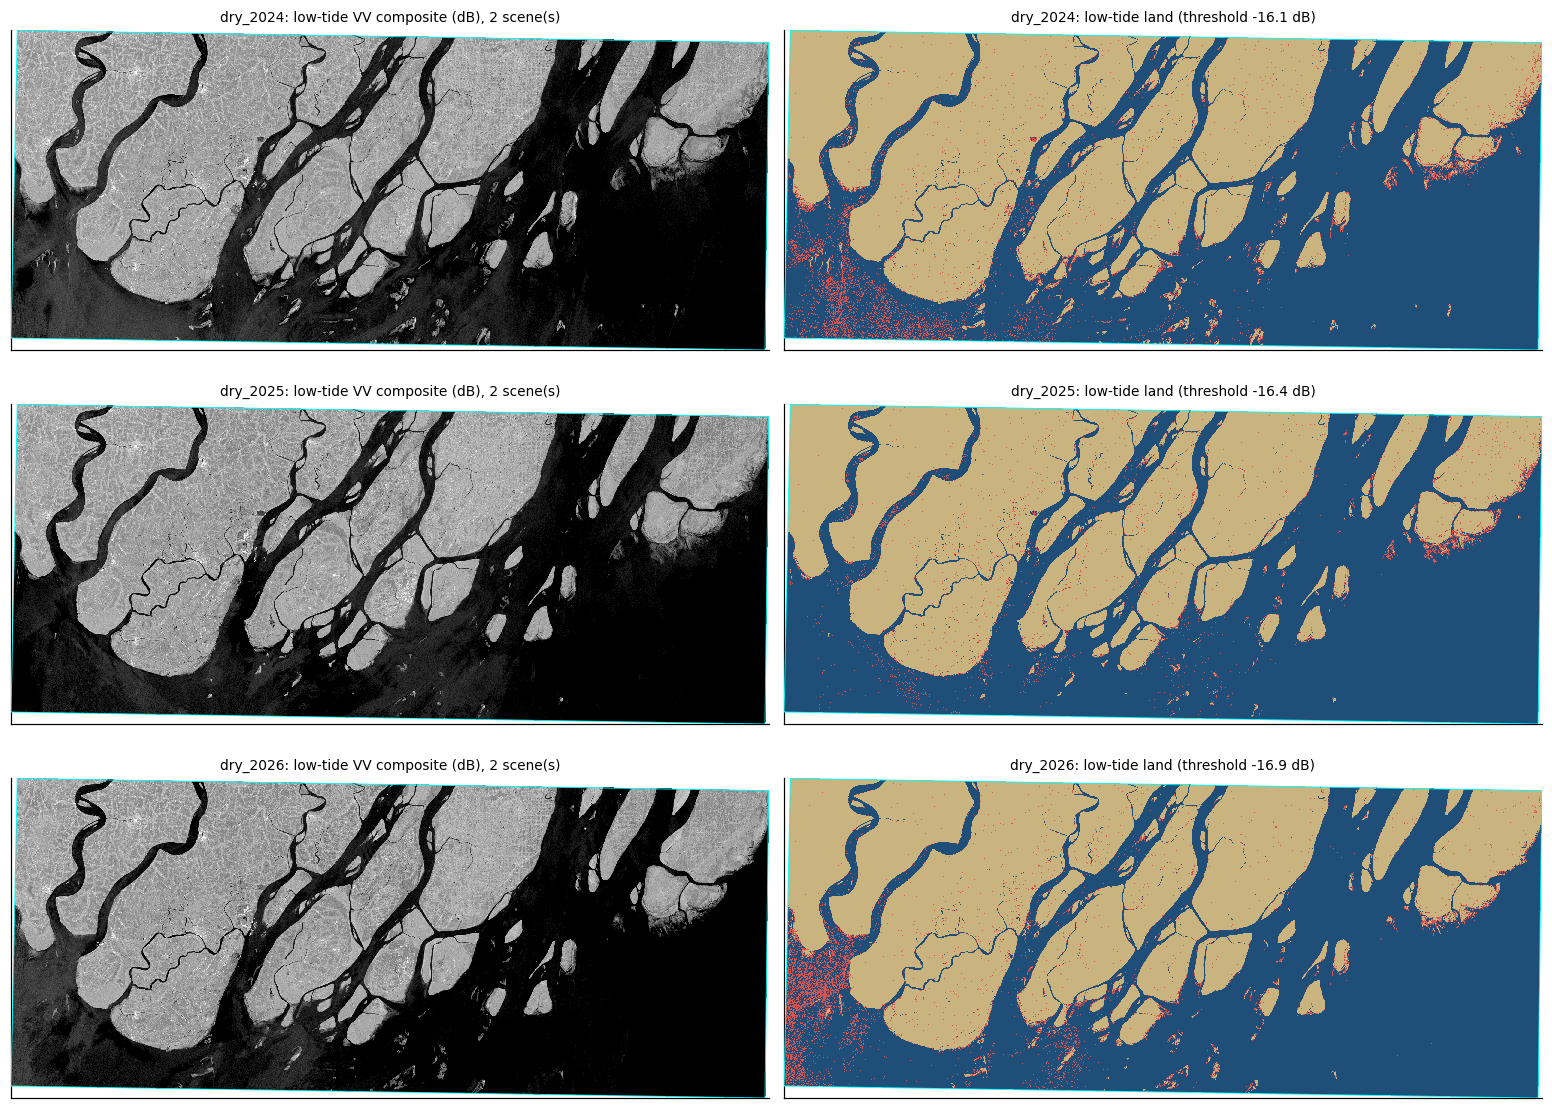

In [ ]:
# Maps: land frequency and classes for the main periods, and the low-tide composite.
show_periods = [p for p in PERIODS if p.startswith("dry_")][-3:] + [p for p in PERIODS if p.startswith("year_")][-1:]
fig, axes = plt.subplots(2, len(show_periods), figsize=(5.2 * len(show_periods), 6.2),
                         constrained_layout=True, squeeze=False)
cmap_c, norm_c = categorical(3, CLASS_COLORS)
for j, name in enumerate(show_periods):
    f = read_band(OUT["annual"] / f"landfreq_{name}.tif", 1, step=DISPLAY_STEP)
    im = show_map(axes[0, j], f, cmap="YlGnBu_r", vmin=0, vmax=1, step=1,
                  title=f"{name}: land frequency ({len(PERIODS[name])} scenes)")
    show_map(axes[1, j], masked_codes(CLASS_MAPS[name]), cmap=cmap_c, norm=norm_c, title=f"{name}: classes")
fig.colorbar(im, ax=axes[0, :], shrink=0.7, label="land frequency")
fig.legend(handles=[Patch(color=c, label=CLASS_NAMES[i]) for i, c in enumerate(CLASS_COLORS)],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
savefig(fig, "land_frequency")
plt.show()

low_keys = [k for k in COMPOSITES if k[1] == "low"]
if low_keys:
    cmap, norm = categorical(3, WATER_COLORS)
    fig, axes = plt.subplots(len(low_keys), 2, figsize=(14, 3.4 * len(low_keys)), constrained_layout=True, squeeze=False)
    for r_, key in enumerate(low_keys):
        name = key[0]
        year = name.split("_")[1]
        comp = read_band(OUT["annual"] / f"lowtide_comp_{year}.tif", 1, step=DISPLAY_STEP)
        show_map(axes[r_, 0], comp, vmin=-25, vmax=0, step=1,
                 title=f"{name}: low-tide VV composite (dB), {len(COMPOSITES[key]['tags'])} scene(s)")
        show_map(axes[r_, 1], masked_codes(COMPOSITES[key]["land"]), cmap=cmap, norm=norm,
                 title=f"{name}: low-tide land (threshold {COMPOSITES[key]['threshold']:.1f} dB)")
        del comp
    savefig(fig, "lowtide_composite")
    plt.show()


## Change detection: accretion, erosion and net change

Each pixel's move between the three classes from period *t* to period *t+1* is labelled as in the protocol:

| Code | From → To | Label |
|---|---|---|
| 0 | no class change | Stable |
| 1 | water → intertidal | Emergence (new deposition) |
| 2 | intertidal → stable land | Consolidation |
| 3 | water → stable land | Rapid accretion (check against imagery) |
| 4 | stable land → intertidal or water | Erosion |
| 5 | intertidal → water | Loss of a young bar |

**Persistence rule.** A change counts only if it holds in the next period's map as well, or appears in both the low-tide and mid-tide composites of year *t+1*. Pixels meeting either test are marked *confirmed* in band 2 of each change raster; totals are reported for all and for confirmed changes.

**Which pairs.** Annual pairs are consecutive complete dry seasons: **dry 2024 → dry 2025** and **dry 2025 → dry 2026**. For the first pair the persistence test uses the dry 2026 map; for the second, the low- and mid-tide composites of 2026. The within-year pair **dry 2024 → November-December 2024** is also kept. It shows the net effect of the 2024 monsoon, but it mixes tide and season with change, so it is labelled *descriptive*. New dry seasons added to the folder extend the pairs automatically.


In [ ]:
# Change codes, persistence confirmation and area statistics.

TRANSITIONS = {0: "Stable", 1: "Emergence", 2: "Consolidation", 3: "Rapid accretion",
               4: "Erosion", 5: "Loss of young bar"}
TRANSITION_COLORS = ["#d9d9d9", "#f6c85f", "#6aa84f", "#1b7837", "#c0392b", "#e67e22"]

def change_codes(a, b):
    out = np.full(a.shape, 255, np.uint8)
    m = (a != 255) & (b != 255)
    out[m] = 0
    out[m & (a == 0) & (b == 1)] = 1
    out[m & (a == 1) & (b == 2)] = 2
    out[m & (a == 0) & (b == 2)] = 3
    out[m & (a == 2) & (b < 2)] = 4
    out[m & (a == 1) & (b == 0)] = 5
    return out

def confirm_change(codes, b_class, next_class=None, low=None, mid=None):
    # 1 confirmed, 0 unconfirmed, 255 not a change / NoData.
    conf = np.full(codes.shape, 255, np.uint8)
    is_change = (codes >= 1) & (codes <= 5)
    conf[is_change] = 0
    gain, loss = np.isin(codes, (1, 2, 3)), np.isin(codes, (4, 5))
    if next_class is not None:
        ok = next_class != 255
        conf[gain & ok & (next_class >= b_class)] = 1
        conf[loss & ok & (next_class <= b_class) & (next_class != 255)] = 1
    if low is not None and mid is not None:
        conf[gain & (low == 1) & (mid == 1)] = 1
        conf[loss & (low == 0) & (mid == 0)] = 1
    return conf

# Consecutive complete dry seasons, plus the within-year demonstration pair.
complete_dry = [p for p in PERIODS if p.startswith("dry_") and len(PERIODS[p]) >= DRY_SEASON_MIN_SCENES]
CHANGE_PAIRS = [(a, b, "annual") for a, b in zip(complete_dry[:-1], complete_dry[1:])
                if int(b.split("_")[1]) == int(a.split("_")[1]) + 1]
for y in years:
    if f"dry_{y}" in PERIODS and f"nov_dec_{y}" in PERIODS:
        CHANGE_PAIRS.append((f"dry_{y}", f"nov_dec_{y}", "within-year (descriptive)"))
if not [p for p in CHANGE_PAIRS if p[2] == "annual"]:
    print("No two consecutive complete dry seasons in the archive: annual change cannot be computed yet.")

CHANGE_MAPS, change_rows, NET_LAND = {}, [], {}
for i, (a, b, kind) in enumerate(CHANGE_PAIRS):
    codes = change_codes(CLASS_MAPS[a], CLASS_MAPS[b])
    common = codes != 255
    NET_LAND[f"{a}__{b}"] = float((np.isin(CLASS_MAPS[b], (1, 2)) & common).sum()
                                  - (np.isin(CLASS_MAPS[a], (1, 2)) & common).sum()) * PIXEL_KM2
    nxt = None
    later = [p for p in CHANGE_PAIRS[i + 1:] if p[0] == b]
    if later:
        nxt = CLASS_MAPS[later[0][1]]
    yb = b.split("_")[-1]
    low = COMPOSITES.get((f"dry_{yb}", "low"), {}).get("land") if b.startswith("dry_") else None
    mid = COMPOSITES.get((f"dry_{yb}", "mid"), {}).get("land") if b.startswith("dry_") else None
    conf = confirm_change(codes, CLASS_MAPS[b], nxt, low, mid)
    tag = f"{a}__{b}"
    write_raster(OUT["change"] / f"change_{tag}.tif", [codes, conf], dtype="uint8", nodata=255,
                 names=["transition_code", "confirmed"])
    CHANGE_MAPS[tag] = (codes, conf, kind)
    for code_, label in TRANSITIONS.items():
        change_rows.append({"pair": tag, "kind": kind, "transition": label,
                            "area_km2": round(float((codes == code_).sum() * PIXEL_KM2), 3),
                            "confirmed_km2": round(float(((codes == code_) & (conf == 1)).sum() * PIXEL_KM2), 3)})
change_table = pd.DataFrame(change_rows)

def gross_net(pair, df):
    acc = df[df.transition.isin(["Emergence", "Consolidation", "Rapid accretion"])]
    ero = df[df.transition.isin(["Erosion", "Loss of young bar"])]
    return pd.Series({"gross_accretion_km2": acc.area_km2.sum(), "gross_erosion_km2": ero.area_km2.sum(),
                      "net_change_km2": acc.area_km2.sum() - ero.area_km2.sum(),
                      "net_land_area_change_km2": NET_LAND[pair],
                      "confirmed_accretion_km2": acc.confirmed_km2.sum(),
                      "confirmed_erosion_km2": ero.confirmed_km2.sum()}, name=pair)
summary_change = (pd.DataFrame([gross_net(p, g) for p, g in change_table.groupby("pair")]).round(3)
                  if len(change_table) else pd.DataFrame())
display(change_table.pivot(index="transition", columns="pair", values="area_km2") if len(change_table) else "no pairs")
display(summary_change)

pair,dry_2024__dry_2025,dry_2024__nov_dec_2024,dry_2025__dry_2026
transition,,,
Consolidation,21.426,20.038,107.336
Emergence,28.592,8.691,62.838
Erosion,122.393,15.996,19.380
Loss of young bar,81.752,105.129,28.400
Rapid accretion,3.816,4.986,6.473
Stable,6684.682,6771.390,6724.967


,gross_accretion_km2,gross_erosion_km2,net_change_km2,net_land_area_change_km2,confirmed_accretion_km2,confirmed_erosion_km2
dry_2024__dry_2025,53.834,204.145,-150.311,-61.452,37.903,93.972
dry_2024__nov_dec_2024,33.715,121.125,-87.410,-101.203,0.000,0.000
dry_2025__dry_2026,176.647,47.780,128.867,37.046,91.380,24.497


*Gross accretion* sums emergence, consolidation and rapid accretion; *gross erosion* sums erosion and loss of young bars; *net change* is their difference (km² of pixels moving up or down the water → intertidal → stable ladder). *Net land-area change* counts only pixels entering or leaving the land classes (intertidal or stable) and therefore matches the difference of land areas between the two class maps.


No unions.gpkg: statistics are reported for the whole AOI only.


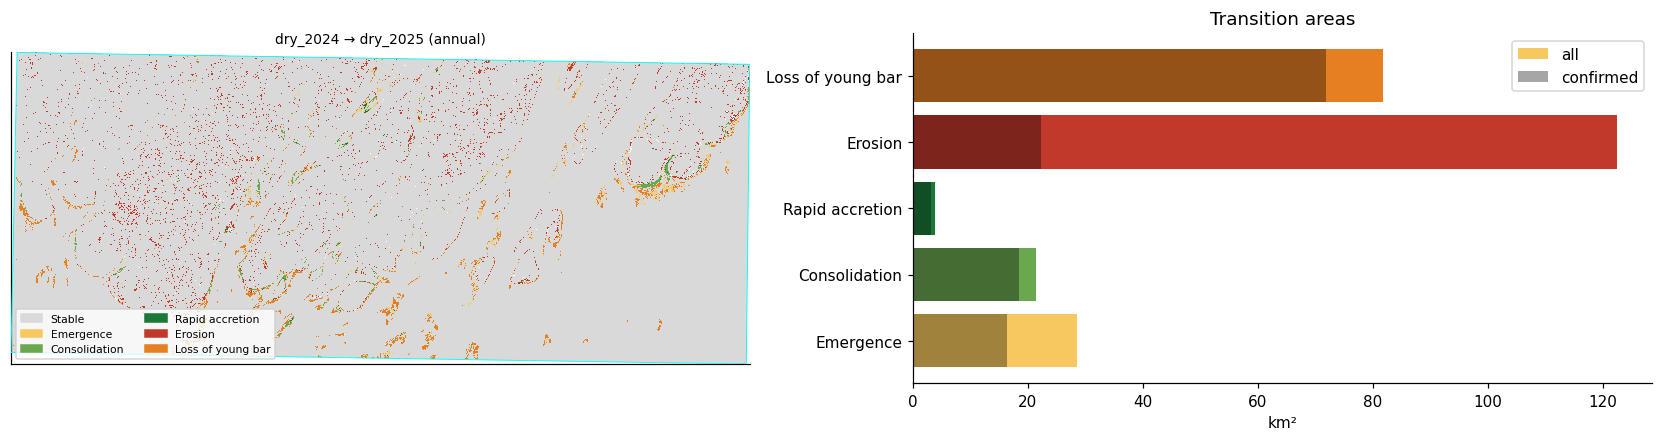

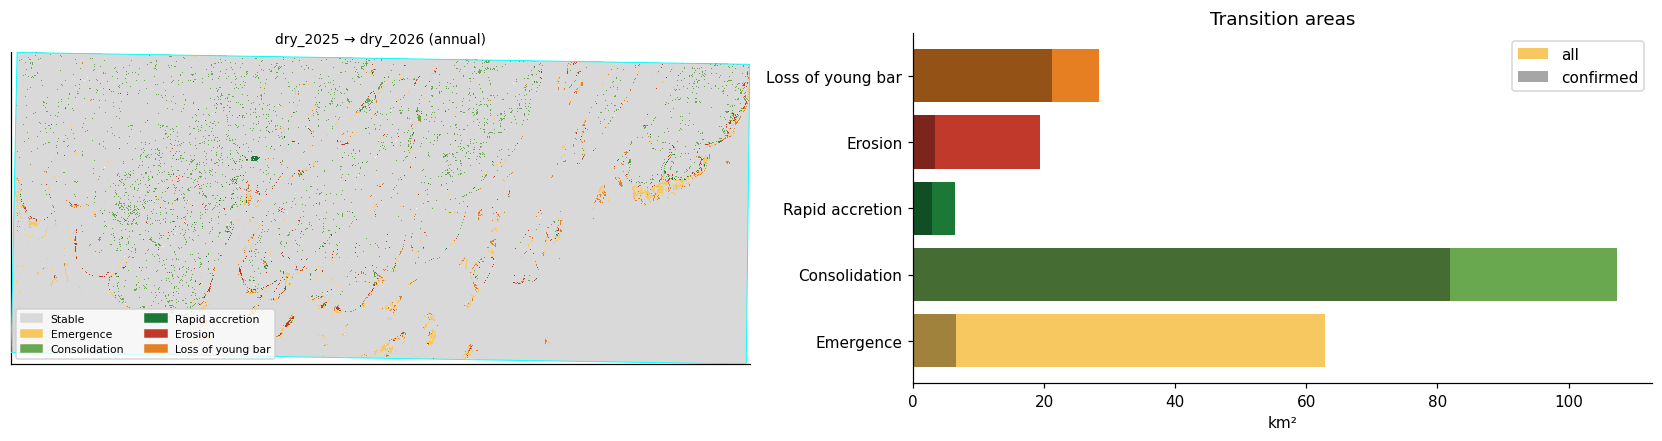

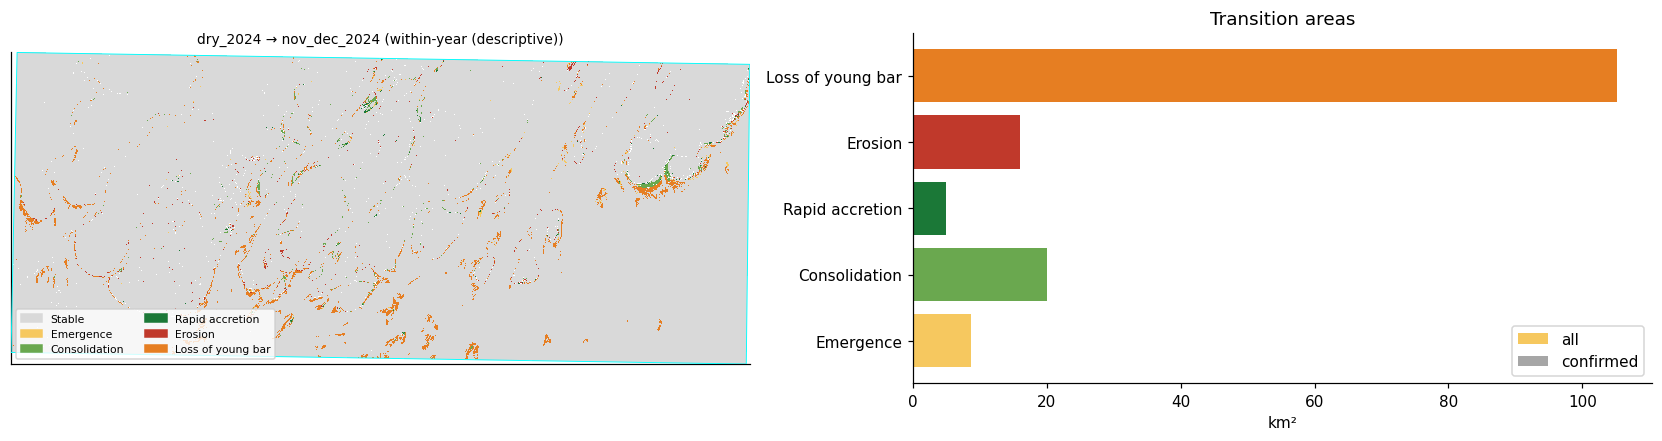

In [ ]:
# Statistics by union (if union boundaries are supplied) and change maps.

if UNIONS_PATH.exists() and CHANGE_MAPS:
    unions = gpd.read_file(UNIONS_PATH).to_crs(GRID_CRS).reset_index(drop=True)
    from rasterio.features import rasterize
    uid = rasterize([(g, i + 1) for i, g in enumerate(unions.geometry)], out_shape=(GRID_H, GRID_W),
                    transform=GRID_TRANSFORM, fill=0, dtype="int32")
    rows_u = []
    for tag, (codes, conf, kind) in CHANGE_MAPS.items():
        for code_, label in TRANSITIONS.items():
            counts = np.bincount(uid[codes == code_], minlength=len(unions) + 1)[1:]
            for i, c in enumerate(counts):
                rows_u.append({"pair": tag, "union": unions.loc[i, "name"] if "name" in unions else i + 1,
                               "transition": label, "area_km2": c * PIXEL_KM2})
    union_table = pd.DataFrame(rows_u)
    union_table.to_csv(OUT["change"] / "change_by_union.csv", index=False)
    display(union_table.pivot_table(index="union", columns="transition", values="area_km2", aggfunc="sum").round(2))
else:
    union_table = None
    print("No unions.gpkg: statistics are reported for the whole AOI only.")

cmap_t, norm_t = categorical(6, TRANSITION_COLORS)
for tag, (codes, conf, kind) in CHANGE_MAPS.items():
    fig, axes = plt.subplots(1, 2, figsize=(15, 3.9), constrained_layout=True)
    show_map(axes[0], masked_codes(codes), cmap=cmap_t, norm=norm_t, title=f"{tag.replace('__', ' → ')} ({kind})")
    axes[0].legend(handles=[Patch(color=c, label=TRANSITIONS[i]) for i, c in enumerate(TRANSITION_COLORS)],
                   loc="lower left", fontsize=7, ncol=2)
    sub = change_table[(change_table.pair == tag) & (change_table.transition != "Stable")]
    axes[1].barh(sub.transition, sub.area_km2, color=TRANSITION_COLORS[1:], label="all")
    axes[1].barh(sub.transition, sub.confirmed_km2, color="k", alpha=0.35, label="confirmed")
    axes[1].set_xlabel("km²"); axes[1].legend(); axes[1].set_title("Transition areas")
    savefig(fig, f"change_{tag}")
    plt.show()

## Char maturity from the backscatter record

Applied to **stable-land** pixels of each calendar year (`year_YYYY`), using the speckle-filtered scenes of that year:

| Code | Stage | Rule used here (protocol signature) |
|---|---|---|
| 1 | Bare, wet sediment | dry-season VV within 3 dB above the scene threshold (near threshold), VH low |
| 2 | Bare, dry sand or silt | moderate VV, low VH, low VH/VV |
| 3 | Grass or crop cover | maximum monthly VH ≥ bare-land baseline + 3 dB, with a seasonal VH swing ≥ 3 dB |
| 4 | Woody cover (planted mangrove, trees) | VH stays high all year (minimum monthly VH ≥ −17 dB) |
| 5 | Settlement | woody-level VH plus bright VV double bounce (dry-season VV ≥ 0 dB) |

The **bare-land baseline** is the 10th percentile of the dry-season VH over stable land. The dB limits are starting values from the C-band literature; calibrate them against VHR imagery of known plantations, crops and bare chars before using the stage areas.


2024: dry threshold -16.21 dB, bare-land VH baseline -18.44 dB


,maturity 2024 (km²)
"Bare, wet sediment",5.50
"Bare, dry sand/silt",99.72
Grass or crop,1225.67
Woody (mangrove/trees),1344.97
Settlement,7.60


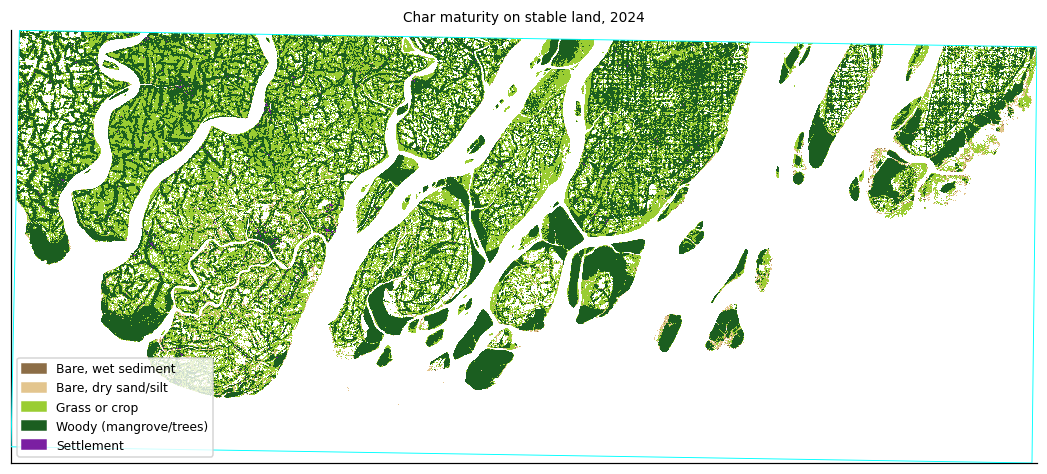

In [ ]:
# Streamed backscatter statistics and the maturity map for each calendar year.

MATURITY_NAMES = {1: "Bare, wet sediment", 2: "Bare, dry sand/silt", 3: "Grass or crop",
                  4: "Woody (mangrove/trees)", 5: "Settlement"}
MATURITY_COLORS = ["#8c6d46", "#e3c58e", "#9acd32", "#1b5e20", "#7b1fa2"]
MATURITY_MAPS = {}
for y in years:
    pname = f"year_{y}"
    if pname not in PERIODS:
        continue
    scenes = PERIODS[pname]
    dry_tags = set(scenes[scenes.season == "dry"].tag) or set(scenes.tag)
    vh_min = np.full((GRID_H, GRID_W), np.inf, "float32"); vh_max = np.full_like(vh_min, -np.inf)
    vv_sum = np.zeros((GRID_H, GRID_W), "float32"); vh_sum = np.zeros_like(vv_sum)
    dcount = np.zeros((GRID_H, GRID_W), "uint8")
    for s in scenes.itertuples():
        sig = OUT["preprocessed"] / f"sigma0_{s.tag}.tif"
        vh = read_band(sig, 2)
        ok = np.isfinite(vh)
        np.minimum(vh_min, np.where(ok, vh, np.inf), out=vh_min)
        np.maximum(vh_max, np.where(ok, vh, -np.inf), out=vh_max)
        if s.tag in dry_tags:
            vv = read_band(sig, 1)
            okd = ok & np.isfinite(vv)
            vv_sum[okd] += vv[okd]; vh_sum[okd] += vh[okd]; dcount += okd
            del vv
        del vh
    with np.errstate(invalid="ignore", divide="ignore"):
        vv_dry = np.where(dcount > 0, vv_sum / dcount, np.nan).astype("float32")
        vh_dry = np.where(dcount > 0, vh_sum / dcount, np.nan).astype("float32")
    del vv_sum, vh_sum
    stable = CLASS_MAPS[pname] == 2
    th_dry = float(np.median(scenes[scenes.tag.isin(dry_tags)].threshold_db))
    baseline = float(np.nanpercentile(vh_dry[stable], 10)) if stable.any() else np.nan
    swing = vh_max - vh_min
    mat = np.full((GRID_H, GRID_W), 255, np.uint8)
    mat[aoi_inside & (CLASS_MAPS[pname] != 255)] = 0
    m = stable & np.isfinite(vv_dry)
    # Rules are applied from the least to the most mature, each overwriting the previous one.
    mat[m & (vv_dry < th_dry + MATURITY["wet_band_db"])] = 1
    mat[m & (vv_dry >= th_dry + MATURITY["wet_band_db"])] = 2
    mat[m & (vh_max >= baseline + MATURITY["veg_rise_db"]) & (swing >= MATURITY["veg_swing_db"])] = 3
    woody = m & (vh_min >= MATURITY["woody_vh_min_db"])
    mat[woody] = 4
    mat[woody & (vv_dry >= MATURITY["settlement_vv_db"])] = 5
    write_raster(OUT["change"] / f"maturity_{y}.tif", mat, dtype="uint8", nodata=255,
                 names=["maturity_stage_1to5_0notstable"])
    MATURITY_MAPS[y] = mat
    del vh_min, vh_max, swing, vv_dry, vh_dry
    areas = {MATURITY_NAMES[k]: round(float((mat == k).sum() * PIXEL_KM2), 2) for k in MATURITY_NAMES}
    print(f"{y}: dry threshold {th_dry:.2f} dB, bare-land VH baseline {baseline:.2f} dB")
    display(pd.Series(areas, name=f"maturity {y} (km²)").to_frame())

    fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
    cm_, nm_ = categorical(5, MATURITY_COLORS)
    show_map(ax, np.where(mat == 0, np.nan, masked_codes(mat) - 1), cmap=cm_, norm=nm_,
             title=f"Char maturity on stable land, {y}")
    ax.legend(handles=[Patch(color=c, label=MATURITY_NAMES[i + 1]) for i, c in enumerate(MATURITY_COLORS)],
              loc="lower left", fontsize=8)
    savefig(fig, f"maturity_{y}")
    plt.show()

## The char register

Every connected land object (intertidal or stable land) larger than 1 ha in a period's class map is a char. Objects are matched to the previous period's objects by **pixel overlap**: the largest overlap inherits the persistent ID, other overlapping pieces are recorded as **splits** with a parent ID, objects with no overlap are **new** (emergence), and earlier chars with no successor are recorded as **lost**. For each char the register stores area, stable-land share, centroid, centroid shift (metres and bearing), period of emergence, age, maturity stage (majority of Step 9 on its stable land) and whether it touches the AOI edge (mainland coast or a char cut by the AOI; these are kept but marked).

Register periods are the complete dry seasons (dry 2024 → dry 2025 → dry 2026), so IDs, centroid shifts and ages are tracked from one dry season to the next. The within-year November-December map is used only when fewer than two complete dry seasons exist.


In [ ]:
# Label chars per period, carry persistent IDs across periods, and write chars_<period>.gpkg.

# With two or more complete dry seasons the register follows the dry seasons only (protocol: year to
# year); otherwise it falls back to every period used in a change pair.
if len(complete_dry) >= 2:
    REGISTER_PERIODS = sorted(complete_dry, key=lambda p: PERIOD_MID[p])
else:
    REGISTER_PERIODS = sorted({p for pair in CHANGE_PAIRS for p in pair[:2]} | set(complete_dry),
                              key=lambda p: PERIOD_MID[p])
if not REGISTER_PERIODS:      # no complete dry season: register the best single period available
    REGISTER_PERIODS = [next(p for p in PERIODS if p.startswith(("dry_", "year_")))]
EIGHT = np.ones((3, 3), bool)
edge_ring = aoi_inside & ~ndi.binary_erosion(aoi_inside, structure=EIGHT, iterations=2)
edge_ring[[0, -1], :] = True; edge_ring[:, [0, -1]] = True

def label_chars(cls):
    land = (cls == 1) | (cls == 2)
    lab, n = ndi.label(land, structure=EIGHT)
    sizes = np.bincount(lab.ravel(), minlength=n + 1)
    keep = sizes >= CHAR_MIN_PX; keep[0] = False
    remap = np.zeros(n + 1, np.int32); remap[keep] = np.arange(1, keep.sum() + 1)
    return remap[lab], int(keep.sum())

def char_table(lab, n, cls, mat):
    ids = np.arange(1, n + 1)
    if n == 0:
        return pd.DataFrame(columns=["label", "area_km2", "stable_km2", "x", "y", "edge", "stable_share",
                                     "maturity", "maturity_name"])
    area = ndi.sum(np.ones_like(lab, np.uint8), lab, ids) * PIXEL_KM2
    stable = ndi.sum(cls == 2, lab, ids) * PIXEL_KM2
    com = np.array(ndi.center_of_mass(np.ones_like(lab, np.uint8), lab, ids)).reshape(-1, 2)
    xs = GRID_TRANSFORM.c + (com[:, 1] + 0.5) * GRID_TRANSFORM.a
    ys = GRID_TRANSFORM.f + (com[:, 0] + 0.5) * GRID_TRANSFORM.e
    edge = ndi.maximum(edge_ring, lab, ids).astype(bool)
    df = pd.DataFrame({"label": ids, "area_km2": area, "stable_km2": stable, "x": xs, "y": ys, "edge": edge})
    df["stable_share"] = (df.stable_km2 / df.area_km2).round(3)
    if mat is not None:
        votes = np.column_stack([ndi.sum(mat == k, lab, ids) for k in MATURITY_NAMES])
        df["maturity"] = np.where(votes.sum(1) > 0, votes.argmax(1) + 1, 0)
        df["maturity_name"] = df.maturity.map(MATURITY_NAMES).fillna("")
    return df

register_rows, prev, next_id = [], None, 1
CHAR_LABELS = {}
for pname in REGISTER_PERIODS:
    cls = CLASS_MAPS[pname]
    lab, n = label_chars(cls)
    year = PERIOD_MID[pname].year
    mat_year = year if year in MATURITY_MAPS else (min(MATURITY_MAPS, key=lambda y_: abs(y_ - year)) if MATURITY_MAPS else None)
    df = char_table(lab, n, cls, MATURITY_MAPS.get(mat_year))
    df["period"] = pname
    df["char_id"], df["status"], df["parent_id"] = "", "new", ""
    df["shift_m"], df["bearing_deg"] = np.nan, np.nan
    if "maturity_name" not in df:
        df["maturity"], df["maturity_name"] = 0, ""
    if prev is None:
        for i in df.index:
            df.loc[i, "char_id"] = f"CH{next_id:05d}"; next_id += 1
        df["first_period"] = pname
    else:
        plab, pdf = prev
        both = (plab > 0) & (lab > 0)
        keys = plab[both].astype(np.int64) * (n + 1) + lab[both]
        uniq, cnt = np.unique(keys, return_counts=True)
        ov = pd.DataFrame({"pa": uniq // (n + 1), "pb": uniq % (n + 1), "n": cnt}).sort_values("n", ascending=False)
        pid = dict(zip(pdf.label, pdf.char_id)); pfirst = dict(zip(pdf.label, pdf.first_period))
        claimed, assigned = set(), {}
        for r_ in ov.itertuples():
            if r_.pb in assigned or r_.pa in claimed:
                continue
            assigned[r_.pb] = r_.pa; claimed.add(r_.pa)
        df["first_period"] = pname
        best_parent = ov.drop_duplicates("pb").set_index("pb").pa.to_dict()
        for i, r_ in df.iterrows():
            if r_.label in assigned:
                pa = assigned[r_.label]
                df.loc[i, ["char_id", "status", "first_period"]] = [pid[pa], "continuing", pfirst[pa]]
            else:
                df.loc[i, "char_id"] = f"CH{next_id:05d}"; next_id += 1
                if r_.label in best_parent:
                    df.loc[i, ["status", "parent_id", "first_period"]] = ["split", pid[best_parent[r_.label]], pname]
        # Centroid shift for continuing chars.
        pxy = pdf.set_index("char_id")[["x", "y"]]
        cont = df.status == "continuing"
        dx = df.loc[cont, "x"].to_numpy() - pxy.loc[df.loc[cont, "char_id"], "x"].to_numpy()
        dy = df.loc[cont, "y"].to_numpy() - pxy.loc[df.loc[cont, "char_id"], "y"].to_numpy()
        df.loc[cont, "shift_m"] = np.hypot(dx, dy).round(1)
        df.loc[cont, "bearing_deg"] = (np.degrees(np.arctan2(dx, dy)) % 360).round(1)
        lost = pdf[~pdf.label.isin(claimed)].copy()
        lost["period"], lost["status"], lost["area_km2"] = pname, "lost", 0.0
        register_rows.append(lost.drop(columns=["label"]))
    df["age_years"] = [round((PERIOD_MID[pname] - PERIOD_MID[fp]).days / 365.25, 2) for fp in df.first_period]
    # Polygons for the period (8-connected shapes of the kept labels).
    geoms = [(shape(g), int(v)) for g, v in shapes(lab, mask=lab > 0, transform=GRID_TRANSFORM, connectivity=8)]
    poly = gpd.GeoDataFrame({"label": [v for _, v in geoms]}, geometry=[g for g, _ in geoms], crs=GRID_CRS)
    poly = poly.dissolve(by="label").reset_index().merge(df, on="label")
    poly.drop(columns=["label"]).to_file(OUT["vectors"] / f"chars_{pname}.gpkg", driver="GPKG")
    register_rows.append(df.drop(columns=["label"]))
    CHAR_LABELS[pname] = (lab, poly)
    prev = (lab, df)
    print(f"{pname}: {n:,} chars >= 1 ha ({int(df.edge.sum())} touch the AOI edge), "
          f"{(df.status == 'continuing').sum()} continuing, {(df.status == 'split').sum()} splits, "
          f"{(df.status == 'new').sum()} new")

char_register = pd.concat(register_rows, ignore_index=True)
char_register.to_csv(OUT["vectors"] / "char_register.csv", index=False)
interior = char_register[~char_register.edge.astype(bool) & (char_register.status != "lost")]
display(interior.sort_values(["period", "area_km2"], ascending=[True, False])
        .groupby("period").head(10)[["period", "char_id", "status", "area_km2", "stable_share",
                                     "shift_m", "bearing_deg", "maturity_name", "first_period", "age_years"]])

dry_2024: 463 chars >= 1 ha (25 touch the AOI edge), 0 continuing, 0 splits, 463 new
dry_2025: 361 chars >= 1 ha (18 touch the AOI edge), 188 continuing, 89 splits, 84 new
dry_2026: 388 chars >= 1 ha (20 touch the AOI edge), 186 continuing, 34 splits, 168 new


,period,char_id,status,area_km2,stable_share,shift_m,bearing_deg,maturity_name,first_period,age_years
97,dry_2024,CH00098,new,241.5652,0.970,NaN,NaN,Woody (mangrove/trees),dry_2024,0.0
142,dry_2024,CH00143,new,97.2797,0.984,NaN,NaN,Woody (mangrove/trees),dry_2024,0.0
69,dry_2024,CH00070,new,53.4002,0.848,NaN,NaN,Woody (mangrove/trees),dry_2024,0.0
209,dry_2024,CH00210,new,52.5483,0.985,NaN,NaN,Woody (mangrove/trees),dry_2024,0.0
309,dry_2024,CH00310,new,32.5535,0.901,NaN,NaN,Woody (mangrove/trees),dry_2024,0.0
78,dry_2024,CH00079,new,31.5643,0.935,NaN,NaN,Woody (mangrove/trees),dry_2024,0.0
96,dry_2024,CH00097,new,28.2242,0.697,NaN,NaN,Grass or crop,dry_2024,0.0
277,dry_2024,CH00278,new,19.7189,0.970,NaN,NaN,Woody (mangrove/trees),dry_2024,0.0
212,dry_2024,CH00213,new,13.7021,0.700,NaN,NaN,Grass or crop,dry_2024,0.0
290,dry_2024,CH00291,new,13.1855,0.974,NaN,NaN,Woody (mangrove/trees),dry_2024,0.0


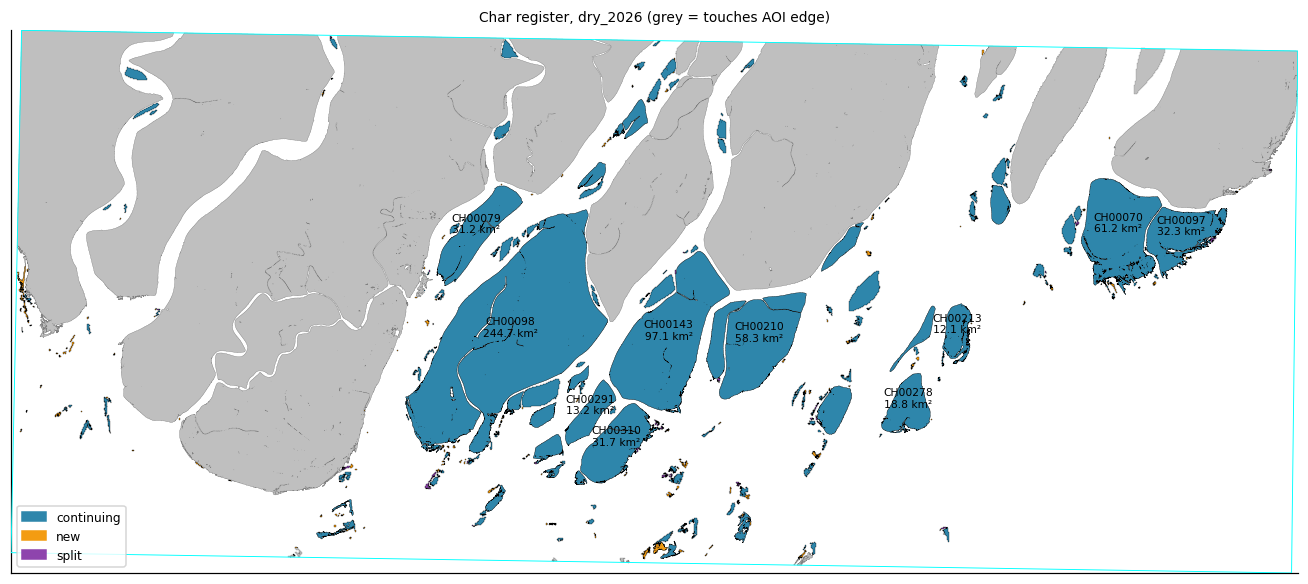

In [ ]:
# Map of the char register for the latest period, with the ten largest interior chars labelled.
last = REGISTER_PERIODS[-1]
lab, poly = CHAR_LABELS[last]
fig, ax = plt.subplots(figsize=(13, 5.2), constrained_layout=True)
show_map(ax, np.full((GRID_H // DISPLAY_STEP, GRID_W // DISPLAY_STEP), np.nan), step=1,
         title=f"Char register, {last} (grey = touches AOI edge)")
status_colors = {"continuing": "#2E86AB", "new": "#f39c12", "split": "#8e44ad"}
for status, color in status_colors.items():
    sub = poly[(poly.status == status) & ~poly.edge.astype(bool)]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="k", linewidth=0.2, label=status)
poly[poly.edge.astype(bool)].plot(ax=ax, color="0.75", edgecolor="0.5", linewidth=0.2)
for r_ in poly[~poly.edge.astype(bool)].nlargest(10, "area_km2").itertuples():
    ax.annotate(f"{r_.char_id}\n{r_.area_km2:.1f} km²", (r_.x, r_.y), fontsize=7, ha="center")
ax.legend(handles=[Patch(color=c, label=s) for s, c in status_colors.items()], loc="lower left", fontsize=8)
savefig(fig, "char_register")
plt.show()

## Shoreline change along DSAS-style transects

The shoreline is the boundary of **stable land** (≥ 90% land frequency) for each register period, with the AOI's own edges removed. Transects are cast every 250 m along the earlier shoreline, perpendicular to it, 1.5 km to each side, and oriented seaward. Where a transect crosses the later shoreline, the signed distance gives the **net shoreline movement** (NSM, m; positive = seaward = accretion) and dividing by the time between the period mid-dates gives the **end-point rate** (EPR, m/yr), as in DSAS. Pairs are consecutive dry seasons plus the full record (first to last dry season).


dry_2024 -> dry_2025: 9,696 transects, 9,658 intersect the later shoreline | NSM median -10.0 m, 10th-90th pct -48 to +31 m | EPR median -10.0 m/yr over 1.00 yr
dry_2025 -> dry_2026: 21,603 transects, 14,932 intersect the later shoreline | NSM median +4.9 m, 10th-90th pct -384 to +390 m | EPR median +4.9 m/yr over 0.99 yr
dry_2024 -> dry_2026: 9,696 transects, 9,511 intersect the later shoreline | NSM median -1.0 m, 10th-90th pct -54 to +34 m | EPR median -0.5 m/yr over 2.00 yr


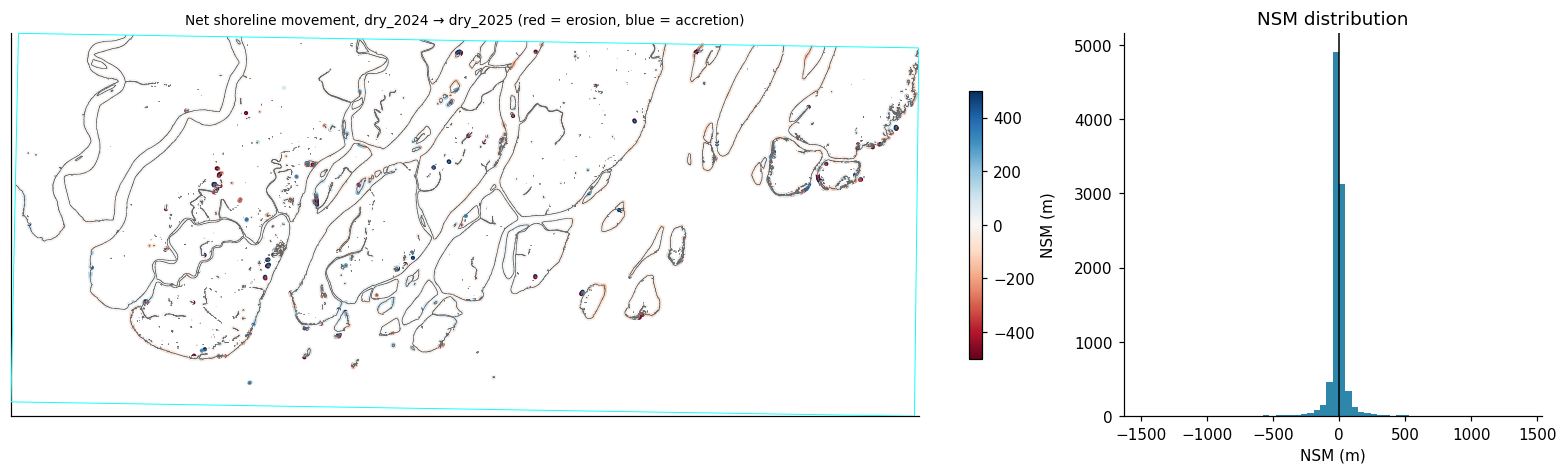

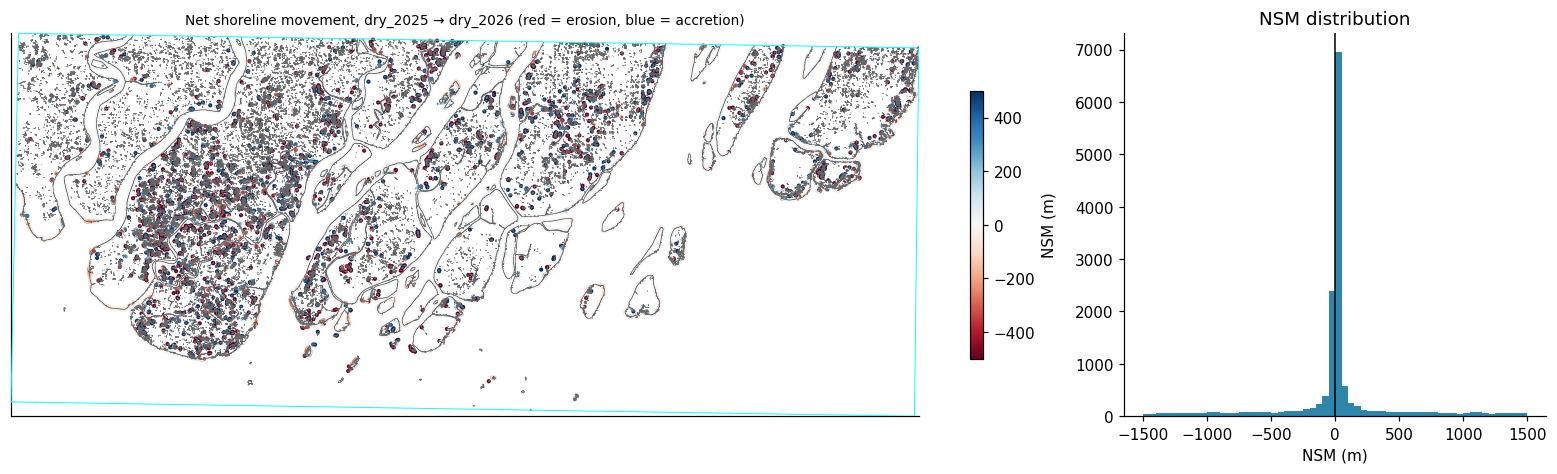

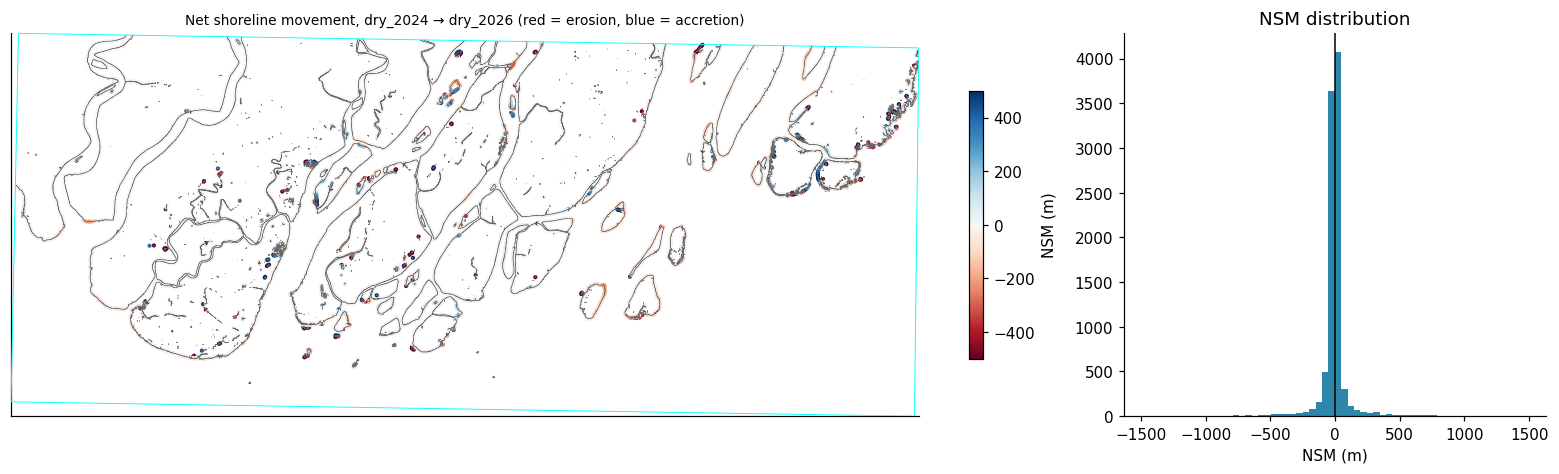

In [ ]:
# Shorelines and transects between consecutive register periods.

def shoreline(pname):
    stable = (CLASS_MAPS[pname] == 2)
    stable = remove_small(stable, CHAR_MIN_PX)
    da = rs.sar.mask_to_polygons(
        xr.DataArray(stable, dims=("y", "x")).rio.write_crs(GRID_CRS).rio.write_transform(GRID_TRANSFORM),
        min_pixels=CHAR_MIN_PX)
    land = unary_union(da.geometry.values) if len(da) else shapely.Polygon()
    inner = aoi_utm.geometry.iloc[0].buffer(-2 * RESOLUTION_M)
    lines = land.boundary.intersection(inner).simplify(RESOLUTION_M / 2)
    gdf = gpd.GeoDataFrame({"period": [pname]}, geometry=[lines], crs=GRID_CRS)
    gdf.to_file(OUT["vectors"] / f"shoreline_{pname}.gpkg", driver="GPKG")
    return land, lines

def explode_lines(geom):
    if geom.is_empty:
        return []
    if geom.geom_type == "LineString":
        return [geom]
    return [g for g in getattr(geom, "geoms", []) if g.geom_type == "LineString"]

SHORE = {p: shoreline(p) for p in REGISTER_PERIODS}
TRANSECTS = {}
SHORE_PAIRS = list(zip(REGISTER_PERIODS[:-1], REGISTER_PERIODS[1:]))
if len(REGISTER_PERIODS) > 2:                     # plus the whole record, first to last dry season
    SHORE_PAIRS.append((REGISTER_PERIODS[0], REGISTER_PERIODS[-1]))
for a, b in SHORE_PAIRS:
    land_a, lines_a = SHORE[a]
    _, lines_b = SHORE[b]
    pts, nrm = [], []
    for line in explode_lines(lines_a):
        L = line.length
        if L < TRANSECT_SPACING_M:
            continue
        for d in np.arange(TRANSECT_SPACING_M / 2, L, TRANSECT_SPACING_M):
            p = line.interpolate(d)
            p1, p2 = line.interpolate(max(d - 25, 0)), line.interpolate(min(d + 25, L))
            tx, ty = p2.x - p1.x, p2.y - p1.y
            norm = math.hypot(tx, ty) or 1.0
            pts.append((p.x, p.y)); nrm.append((-ty / norm, tx / norm))
    if not pts:
        print(f"{a} -> {b}: no shoreline long enough for transects"); continue
    pts, nrm = np.array(pts), np.array(nrm)
    # Orient normals seaward: a point 15 m along the normal must fall outside land_a.
    shapely.prepare(land_a)
    inside = shapely.contains_xy(land_a, pts[:, 0] + 15 * nrm[:, 0], pts[:, 1] + 15 * nrm[:, 1])
    nrm[inside] *= -1
    t_lines = shapely.linestrings(np.stack([pts - TRANSECT_HALF_LEN_M * nrm, pts + TRANSECT_HALF_LEN_M * nrm], 1))
    parts_b = explode_lines(lines_b)
    nsm = np.full(len(pts), np.nan)
    if parts_b:
        tree = STRtree(parts_b)
        ti, si = tree.query(t_lines, predicate="intersects")
        for t, s in zip(ti, si):
            inter = t_lines[t].intersection(parts_b[s])
            for q in getattr(inter, "geoms", [inter]):
                if q.geom_type != "Point":
                    continue
                d = (q.x - pts[t, 0]) * nrm[t, 0] + (q.y - pts[t, 1]) * nrm[t, 1]
                if np.isnan(nsm[t]) or abs(d) < abs(nsm[t]):
                    nsm[t] = d
    dt_years = (PERIOD_MID[b] - PERIOD_MID[a]).days / 365.25
    tr = gpd.GeoDataFrame({"pair": f"{a}__{b}", "nsm_m": np.round(nsm, 1),
                           "epr_m_yr": np.round(nsm / dt_years, 1)}, geometry=t_lines, crs=GRID_CRS)
    tr.to_file(OUT["vectors"] / "transects.gpkg", layer=f"{a}__{b}", driver="GPKG")
    TRANSECTS[(a, b)] = tr
    ok = tr.nsm_m.notna()
    print(f"{a} -> {b}: {len(tr):,} transects, {ok.sum():,} intersect the later shoreline | "
          f"NSM median {tr.nsm_m.median():+.1f} m, 10th-90th pct {tr.nsm_m.quantile(.1):+.0f} to "
          f"{tr.nsm_m.quantile(.9):+.0f} m | EPR median {tr.epr_m_yr.median():+.1f} m/yr over {dt_years:.2f} yr")

for (a, b), tr in TRANSECTS.items():
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2.4, 1]}, constrained_layout=True)
    show_map(axes[0], np.full((GRID_H // DISPLAY_STEP, GRID_W // DISPLAY_STEP), np.nan), step=1,
             title=f"Net shoreline movement, {a} → {b} (red = erosion, blue = accretion)")
    gpd.GeoSeries([SHORE[a][1]], crs=GRID_CRS).plot(ax=axes[0], color="0.4", linewidth=0.4)
    cen = tr.copy(); cen["geometry"] = tr.geometry.interpolate(0.5, normalized=True)
    cen[cen.nsm_m.notna()].plot(ax=axes[0], column="nsm_m", cmap="RdBu", vmin=-500, vmax=500, markersize=3, legend=True,
                               legend_kwds={"label": "NSM (m)", "shrink": 0.7})
    axes[1].hist(tr.nsm_m.dropna().clip(-1500, 1500), bins=60, color="#2E86AB")
    axes[1].axvline(0, color="k", lw=1); axes[1].set_xlabel("NSM (m)"); axes[1].set_title("NSM distribution")
    savefig(fig, f"shoreline_{a}__{b}")
    plt.show()

## Long-term pixel history and the intertidal elevation surface

**Pixel history.** With two or more complete dry seasons, each pixel gets the dry-season year in which it **first emerged** (first year as intertidal or stable land after being water) and the year it was **lost** (first year back to water after being land), if any. With dry seasons 2024, 2025 and 2026, a pixel can first emerge or be lost in 2025 or 2026.

**Intertidal elevation (optional, waterline method).** If tide heights are in metres (gauge CSV or pyTMD), each intertidal pixel's elevation lies between the highest tide at which it was seen as land and the lowest tide at which it was seen as water; the midpoint is written to `annual/intertidal_elevation_YYYY.tif`. This shows a char building up vertically before it appears in the area figures.


In [ ]:
# Pixel history over complete dry seasons, and the optional intertidal elevation surface.

def pixel_history(period_names):
    stack = np.stack([CLASS_MAPS[p] for p in period_names])
    yrs = np.array([int(p.split("_")[1]) for p in period_names])
    land = (stack == 1) | (stack == 2); water = stack == 0
    first_em = np.zeros(stack.shape[1:], np.uint16); loss = np.zeros_like(first_em)
    seen_water = water[0].copy(); seen_land = land[0].copy()
    for k in range(1, len(yrs)):
        new = seen_water & land[k] & (first_em == 0)
        first_em[new] = yrs[k]
        gone = seen_land & water[k] & (loss == 0)
        loss[gone] = yrs[k]
        seen_water |= water[k]; seen_land |= land[k]
    return first_em, loss

if len(complete_dry) >= 2:
    first_em, loss = pixel_history(complete_dry)
    write_raster(OUT["annual"] / "first_emergence_year.tif", first_em, dtype="uint16", nodata=0)
    write_raster(OUT["annual"] / "loss_year.tif", loss, dtype="uint16", nodata=0)
    print("Pixel history written for", complete_dry)
else:
    print(f"Pixel history needs >= 2 complete dry seasons; the archive has {len(complete_dry)} ({complete_dry}).")

if TIDE_IN_METRES:
    for y in years:
        pname = f"year_{y}"
        if pname not in PERIODS:
            continue
        land_max = np.full((GRID_H, GRID_W), -np.inf, "float32"); water_min = np.full_like(land_max, np.inf)
        for s in PERIODS[pname].itertuples():
            c = read_band(OUT["classified"] / f"water_{s.tag}.tif", 1)
            land_max[c == 1] = np.maximum(land_max[c == 1], s.tide_m)
            water_min[c == 0] = np.minimum(water_min[c == 0], s.tide_m)
        inter = (CLASS_MAPS[pname] == 1) & np.isfinite(land_max) & np.isfinite(water_min)
        elev = np.where(inter, (land_max + water_min) / 2, np.nan).astype("float32")
        write_raster(OUT["annual"] / f"intertidal_elevation_{y}.tif", elev, dtype="float32", nodata=np.nan)
        print(f"{y}: intertidal elevation for {inter.sum() * PIXEL_KM2:,.1f} km² (m above MSL)")
else:
    print("Intertidal elevation skipped: tide heights in metres are needed (add scene_tide.csv or pyTMD).")

Pixel history written for ['dry_2024', 'dry_2025', 'dry_2026']
Intertidal elevation skipped: tide heights in metres are needed (add scene_tide.csv or pyTMD).


## NISAR L-band GCOV as a parallel series

NISAR GCOV products are geocoded, radiometrically terrain-corrected covariance (γ⁰) on a map grid. The files here are dual-pol (`DHDH`: HH and HV). L-band penetrates further into vegetation and is less sensitive to small waves than C-band, so open water stays dark in HH even in the monsoon. Following the protocol, NISAR is **never mixed** into the Sentinel-1 series. It is processed as its own series, one track at a time:

1. read only the AOI window of `HHHH` and `HVHV` (and `mask`, `numberOfLooks`) from each HDF5 file with `h5py` slicing, so the 2.5 to 6 GB files are never loaded whole;
2. Refined Lee with the product's number of looks, then reprojection onto the master grid;
3. the same tile-threshold classifier on HH dB;
4. monsoon 2026 land frequency for the main NISAR track, compared with the Sentinel-1 monsoon 2024 map.

The 2024 → 2026 comparison mixes two sensors, two wavelengths, two years and different tides; it is a **descriptive cross-check**, not a change estimate.

*Check for your product release:* the GCOV `mask` convention. Here 0 and 255 are treated as invalid (no sample / outside the geocoded swath); the cell prints the values found and falls back to finite, positive γ⁰ if the mask would remove almost everything. The x/y coordinate arrays are taken as pixel centres (a half-pixel error would be 10 m at most).


### NISAR inventory and the layers available in the GCOV grid group.


In [ ]:
# NISAR inventory and the layers available in the GCOV grid group.
import h5py

def parse_nisar_name(path):
    p = path.stem.split("_")
    return {"file": path, "cycle": int(p[4]), "track": int(p[5]),
            "direction": {"A": "ASCENDING", "D": "DESCENDING"}.get(p[6], p[6]), "frame": int(p[7]),
            "mode": p[8], "pols": p[9], "time_utc": pd.Timestamp(datetime.strptime(p[11], "%Y%m%dT%H%M%S")),
            "size_gb": round(path.stat().st_size / 1e9, 2)}

nisar_files = sorted(NISAR_DIR.glob("NISAR_L2_*GCOV*.h5"))
nisar = pd.DataFrame([parse_nisar_name(f) for f in nisar_files])
if len(nisar):
    nisar["date"] = nisar.time_utc.dt.normalize()
    nisar["tag"] = nisar.time_utc.dt.strftime("%Y%m%d") + "_T" + nisar.track.astype(str).str.zfill(3) + nisar.direction.str[0]
    with h5py.File(nisar.file.iloc[0], "r") as f:
        layers = sorted(k for k in f[GCOV_GRID].keys())
    print("GCOV frequencyA layers:", layers)
    display(nisar.drop(columns=["file"]))
else:
    print("No NISAR GCOV files found in", NISAR_DIR)

GCOV frequencyA layers: ['HHHH', 'HVHV', 'inputDataExceptionMask', 'listOfCovarianceTerms', 'listOfPolarizations', 'mask', 'numberOfLooks', 'numberOfSubSwaths', 'projection', 'rtcGammaToSigmaFactor', 'xCoordinateSpacing', 'xCoordinates', 'yCoordinateSpacing', 'yCoordinates']


,cycle,track,direction,frame,mode,pols,time_utc,size_gb,date,tag
0,25,41,DESCENDING,66,4005,DHDH,2026-07-11 01:14:45,4.45,2026-07-11,20260711_T041D
1,26,69,ASCENDING,13,4005,DHDH,2026-07-24 23:20:59,6.27,2026-07-24,20260724_T069A
2,28,69,ASCENDING,13,4005,DHDH,2026-08-17 23:20:58,6.26,2026-08-17,20260817_T069A
3,30,69,ASCENDING,13,4005,DHDH,2026-09-10 23:20:58,6.11,2026-09-10,20260910_T069A
4,33,69,ASCENDING,13,4005,DHDH,2026-10-16 23:20:58,6.25,2026-10-16,20261016_T069A


### Data Processing


In [ ]:
# Windowed read, speckle filter and reprojection of each GCOV scene onto the master grid.

def read_gcov_window(path, pols=("HHHH", "HVHV")):
    with h5py.File(path, "r") as f:
        g = f[GCOV_GRID]
        x, y = g["xCoordinates"][:], g["yCoordinates"][:]
        epsg = int(np.asarray(g["projection"][()]).ravel()[0])
        l, b, r, t = transform_bounds("EPSG:4326", f"EPSG:{epsg}", *AOI_BOUNDS, densify_pts=21)
        dx, dy = float(x[1] - x[0]), float(y[1] - y[0])
        pad = 5 * abs(dx)
        ix = np.flatnonzero((x >= l - pad) & (x <= r + pad))
        iy = np.flatnonzero((y >= b - pad) & (y <= t + pad))
        if ix.size == 0 or iy.size == 0:
            return None
        sl = (slice(iy.min(), iy.max() + 1), slice(ix.min(), ix.max() + 1))
        data = {p: g[p][sl].astype("float32") for p in pols if p in g}
        mask = g["mask"][sl] if "mask" in g else None
        looks = float(np.nanmedian(g["numberOfLooks"][sl])) if "numberOfLooks" in g else 4.0
    valid = np.ones(next(iter(data.values())).shape, bool)
    for arr in data.values():
        valid &= np.isfinite(arr) & (arr > 0)
    mask_values = None
    if mask is not None:
        mask_values = np.unique(mask[::50, ::50])
        mvalid = valid & (mask != 0) & (mask != 255)
        if mvalid.sum() > 0.01 * valid.sum():
            valid = mvalid
    for p in data:
        data[p][~valid] = np.nan
    x0, y0 = float(x[ix.min()]), float(y[iy.min()])
    transform = Affine(dx, 0, x0 - dx / 2, 0, dy, y0 - dy / 2)
    if dy > 0:                                   # make the window north-up
        data = {p: a[::-1] for p, a in data.items()}
        transform = Affine(dx, 0, x0 - dx / 2, 0, -dy, float(y[iy.max()]) + dy / 2)
    return {"data": data, "transform": transform, "crs": f"EPSG:{epsg}", "looks": looks,
            "posting_m": abs(dx), "mask_values": mask_values}

def to_master(arr, src_transform, src_crs):
    dst = np.full((GRID_H, GRID_W), np.nan, "float32")
    reproject(arr, dst, src_transform=src_transform, src_crs=src_crs, dst_transform=GRID_TRANSFORM,
              dst_crs=GRID_CRS, resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
    dst[~aoi_inside] = np.nan
    return dst

nisar_rows = []
for s in nisar.itertuples():
    out_path = NISAR_OUT / f"gcov_{s.tag}.tif"
    cls_path = OUT["classified"] / f"nisar_water_{s.tag}.tif"
    if not (out_path.exists() and cls_path.exists()) or OVERWRITE:
        win = read_gcov_window(s.file)
        if win is None:
            print(f"{s.tag}: frame does not intersect the AOI"); continue
        dbs = {}
        for p, arr in win["data"].items():
            filt = blockwise(lambda a: rs.sar.refined_lee(a, enl=win["looks"]), arr)
            dbs[p] = rs.sar.to_db(to_master(filt, win["transform"], win["crs"]))
        hh, hv = dbs["HHHH"], dbs.get("HVHV", np.full_like(dbs["HHHH"], np.nan))
        write_raster(out_path, [hh, hv], dtype="float32", nodata=np.nan, names=["HH_gamma0_dB", "HV_gamma0_dB"])
        valid = np.isfinite(hh) & aoi_inside
        th, ntile, _ = tile_threshold(hh, valid)
        cls = classify_db(hh, valid, th)
        write_raster(cls_path, cls, dtype="uint8", nodata=255, names=["water0_land1_uncertain2"])
        meta = {"threshold_db": th, "n_tiles": ntile, "looks": win["looks"], "posting_m": win["posting_m"],
                "crs": win["crs"], "mask_values": [int(v) for v in (win["mask_values"] if win["mask_values"] is not None else [])]}
        (NISAR_OUT / f"gcov_{s.tag}.json").write_text(json.dumps(meta))
        del win, dbs, hh, hv, cls
    meta = json.loads((NISAR_OUT / f"gcov_{s.tag}.json").read_text())
    cls = read_band(cls_path, 1)
    cover = float(((cls != 255) & aoi_inside).sum() / aoi_inside.sum())
    nisar_rows.append({"tag": s.tag, "aoi_cover": round(cover, 3), **meta,
                       "water_frac": float((cls == 0).sum() / max(1, (cls != 255).sum())),
                       "uncertain_frac": float((cls == 2).sum() / max(1, (cls != 255).sum()))})
    print(f"{s.tag}: posting {meta['posting_m']:.0f} m, {meta['looks']:.0f} looks, HH threshold "
          f"{meta['threshold_db']:.2f} dB ({meta['n_tiles']} tiles), AOI cover {cover:.1%}, mask values {meta['mask_values']}")
    del cls
nisar_stats = pd.DataFrame(nisar_rows)
nisar = nisar.merge(nisar_stats, on="tag", how="left") if len(nisar_stats) else nisar
skipped = nisar.tag[nisar.get("aoi_cover", pd.Series(np.nan, index=nisar.index)).isna()].tolist()
if skipped:
    print("Not processed (no AOI overlap):", skipped)

20260711_T041D: frame does not intersect the AOI
20260724_T069A: posting 10 m, 5 looks, HH threshold -10.27 dB (592 tiles), AOI cover 97.5%, mask values [0, 1, 255]
20260817_T069A: posting 10 m, 5 looks, HH threshold -9.46 dB (579 tiles), AOI cover 97.6%, mask values [0, 1, 255]
20260910_T069A: posting 10 m, 5 looks, HH threshold -9.96 dB (600 tiles), AOI cover 97.5%, mask values [0, 1, 255]
20261016_T069A: posting 10 m, 5 looks, HH threshold -9.65 dB (562 tiles), AOI cover 97.6%, mask values [0, 1, 255]
Not processed (no AOI overlap): ['20260711_T041D']


### NISAR land frequency for the main track and the cross-sensor comparison with Sentinel-1.


nisar_T069A_2026_monsoon: 4 scenes ['2026-07-24', '2026-08-17', '2026-09-10', '2026-10-16']
Overlap of S1 monsoon_2024 and NISAR nisar_T069A_2026_monsoon: 6,681 km² (areas in km²)


NISAR nisar_T069A_2026_monsoon,Intertidal,Permanent water,Stable land
S1 monsoon_2024,,,
Intertidal,324.8,346.0,200.8
Permanent water,6.1,3512.5,19.5
Stable land,336.6,350.7,1584.3


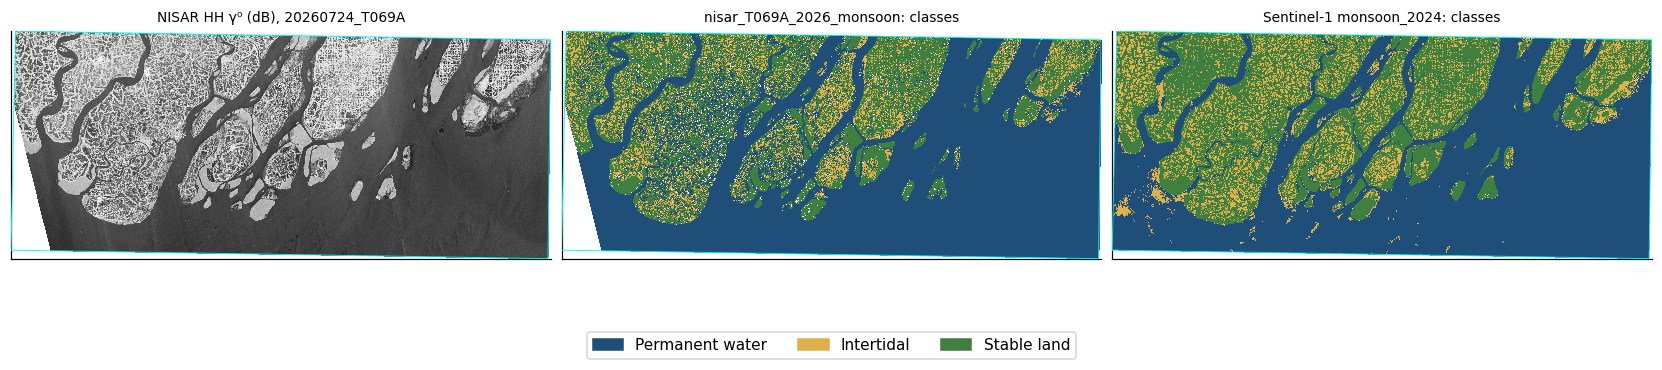

In [ ]:
# NISAR land frequency for the main track and the cross-sensor comparison with Sentinel-1.

NISAR_RESULT = None
if len(nisar) and "aoi_cover" in nisar:
    ok = nisar[nisar.aoi_cover >= NISAR_MIN_COVER]
    if ok.empty:
        ok = nisar[nisar.aoi_cover >= 0.5]
        print(f"No NISAR scene covers >= {NISAR_MIN_COVER:.0%} of the AOI; using scenes with >= 50% (flagged).")
    if len(ok):
        main = ok.groupby(["track", "direction"]).size().sort_values(ascending=False).index[0]
        series = ok[(ok.track == main[0]) & (ok.direction == main[1])].sort_values("time_utc")
        land = np.zeros((GRID_H, GRID_W), np.uint16); valid = np.zeros_like(land)
        for t in series.tag:
            c = read_band(OUT["classified"] / f"nisar_water_{t}.tif", 1)
            land += c == 1; valid += (c == 0) | (c == 1)
        with np.errstate(invalid="ignore", divide="ignore"):
            nfreq = np.where(valid > 0, land / valid, np.nan).astype("float32")
        nfreq[~aoi_inside] = np.nan
        ncls = frequency_classes(nfreq)
        months = series.time_utc.dt.month
        label = f"nisar_T{main[0]:03d}{main[1][0]}_{series.time_utc.dt.year.iloc[0]}_" + \
                ("monsoon" if months.isin(MONSOON_MONTHS).all() else "mixed")
        write_raster(OUT["annual"] / f"landfreq_{label}.tif", nfreq, dtype="float32", nodata=np.nan)
        write_raster(OUT["annual"] / f"class_{label}.tif", ncls, dtype="uint8", nodata=255)
        ref_name = next((p for p in [f"monsoon_{y}" for y in years[::-1]] if p in CLASS_MAPS), None)
        NISAR_RESULT = {"label": label, "tags": list(series.tag), "class": ncls, "ref": ref_name}
        print(f"{label}: {len(series)} scenes {list(series.date.dt.strftime('%Y-%m-%d'))}")
        if ref_name:
            both = (ncls != 255) & (CLASS_MAPS[ref_name] != 255)
            xtab = pd.crosstab(pd.Series(CLASS_MAPS[ref_name][both]).map(CLASS_NAMES).rename(f"S1 {ref_name}"),
                               pd.Series(ncls[both]).map(CLASS_NAMES).rename(f"NISAR {label}")) * PIXEL_KM2
            print(f"Overlap of S1 {ref_name} and NISAR {label}: {both.sum() * PIXEL_KM2:,.0f} km² (areas in km²)")
            display(xtab.round(1))
            xcodes = change_codes(CLASS_MAPS[ref_name], ncls)
            write_raster(OUT["change"] / f"change_{ref_name}__{label}.tif", xcodes, dtype="uint8", nodata=255,
                         names=["transition_code_cross_sensor"])
            NISAR_RESULT["xtab"] = xtab
            NISAR_RESULT["codes"] = xcodes

if NISAR_RESULT:
    # Other-track scenes that were actually classified (a frame outside the AOI has no output file).
    other = nisar[~nisar.tag.isin(NISAR_RESULT["tags"])]
    other = other[[(OUT["classified"] / f"nisar_water_{t}.tif").exists() for t in other.tag]]
    ncols = 2 + (1 if NISAR_RESULT.get("ref") else 0) + len(other)
    fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 3.6), constrained_layout=True)
    first = NISAR_OUT / f"gcov_{NISAR_RESULT['tags'][0]}.tif"
    show_map(axes[0], read_band(first, 1, step=DISPLAY_STEP), vmin=-25, vmax=0, step=1,
             title=f"NISAR HH γ⁰ (dB), {NISAR_RESULT['tags'][0]}")
    show_map(axes[1], masked_codes(NISAR_RESULT["class"]), cmap=cmap_c, norm=norm_c,
             title=f"{NISAR_RESULT['label']}: classes")
    k = 2
    if NISAR_RESULT.get("ref"):
        show_map(axes[2], masked_codes(CLASS_MAPS[NISAR_RESULT["ref"]]), cmap=cmap_c, norm=norm_c,
                 title=f"Sentinel-1 {NISAR_RESULT['ref']}: classes"); k = 3
    for ax, t in zip(axes[k:], other.tag):
        show_map(ax, masked_codes(read_band(OUT["classified"] / f"nisar_water_{t}.tif", 1, step=DISPLAY_STEP)),
                 cmap=ListedColormap(WATER_COLORS), norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3), step=1,
                 title=f"NISAR {t} (separate track)")
    fig.legend(handles=[Patch(color=c, label=CLASS_NAMES[i]) for i, c in enumerate(CLASS_COLORS)],
               loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
    savefig(fig, "nisar")
    plt.show()

### NISAR and Sentinel-1 class maps on satellite imagery

The two class maps above are shown side by side on Esri World Imagery. The maps are linked, so panning or zooming one moves the other. Use the layer control (top right) to change the overlay opacity or hide it, and compare the classes with the char shapes visible in the image.


In [ ]:
# Interactive comparison of the NISAR and Sentinel-1 class maps on satellite imagery (needs leafmap).
# Two linked maps (pan or zoom one and the other follows); each layer has an opacity slider in the
# layer control, so the satellite image underneath can be checked against the classes.
import io
from ipywidgets import HBox, Layout, jslink
from rasterio.transform import array_bounds
from rasterio.warp import calculate_default_transform

LEAF_RES_M = 30            # display resolution of the overlays (10 m works but is slower)
LEAF_OPACITY = 0.70

def class_overlay(cls, name, colors=CLASS_COLORS, res_m=LEAF_RES_M, opacity=LEAF_OPACITY):
    """Class codes on the master grid -> transparent PNG ImageOverlay in Web Mercator."""
    from ipyleaflet import ImageOverlay
    src = np.where(aoi_inside, cls, 255).astype("uint8")
    left, bottom, right, top = array_bounds(GRID_H, GRID_W, GRID_TRANSFORM)
    tr, w, h = calculate_default_transform(GRID_CRS, "EPSG:3857", GRID_W, GRID_H,
                                           left, bottom, right, top, resolution=res_m)
    dst = np.full((h, w), 255, "uint8")
    reproject(src, dst, src_transform=GRID_TRANSFORM, src_crs=GRID_CRS, dst_transform=tr,
              dst_crs="EPSG:3857", resampling=Resampling.nearest, src_nodata=255, dst_nodata=255)
    lut = np.zeros((256, 4), "uint8")                       # code 255 stays fully transparent
    for code, hexcol in enumerate(colors):
        lut[code] = [int(hexcol[i:i + 2], 16) for i in (1, 3, 5)] + [255]
    buf = io.BytesIO()
    plt.imsave(buf, lut[dst], format="png")
    url = "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()
    w84, s84, e84, n84 = transform_bounds("EPSG:3857", "EPSG:4326", tr.c, tr.f + h * tr.e, tr.c + w * tr.a, tr.f)
    return ImageOverlay(url=url, bounds=((s84, w84), (n84, e84)), name=name, opacity=opacity)

def class_leafmap(cls, title):
    west, south, east, north = AOI_BOUNDS
    m = leafmap.Map(center=((south + north) / 2, (west + east) / 2), zoom=10, height="560px",
                    draw_control=False, measure_control=False)
    m.add_basemap("Esri.WorldImagery")
    m.add_layer(class_overlay(cls, title))
    m.add_gdf(aoi, layer_name="Charland AOI", style={"color": "#00e5ff", "weight": 2, "fillOpacity": 0})
    m.add_legend(title=title, legend_dict={CLASS_NAMES[i]: CLASS_COLORS[i] for i in CLASS_NAMES},
                 position="bottomright")
    m.add_layer_control()
    m.layout.width = "50%"
    return m

try:
    import leafmap
    if NISAR_RESULT and NISAR_RESULT.get("ref"):
        m_nisar = class_leafmap(NISAR_RESULT["class"], f"NISAR {NISAR_RESULT['label']}")
        m_s1 = class_leafmap(CLASS_MAPS[NISAR_RESULT["ref"]], f"Sentinel-1 {NISAR_RESULT['ref']}")
        jslink((m_nisar, "center"), (m_s1, "center"))
        jslink((m_nisar, "zoom"), (m_s1, "zoom"))
        display(HBox([m_nisar, m_s1], layout=Layout(width="100%")))
    else:
        print("No NISAR result with a Sentinel-1 reference period; nothing to map.")
except ImportError:
    print("leafmap is not installed; skipping the interactive maps.")

## Validation: sample design, reference labels and accuracy

The protocol requires stratified random samples, at least 50 points per mapped class (and per change class), labelled on imagery that shares nothing with the classifier, and area estimates adjusted for map error with 95% confidence intervals (Olofsson et al. 2014).

No reference imagery or field points are in the folder, so this step does what can be done now:

1. **Sample design.** It writes the sample files `validation/ref_points_*.gpkg` (class-map, change-map and single-date samples) with an empty `ref_class` column. Open them in QGIS over cloud-free Sentinel-2 or Landsat (within 3 days and ±0.3 m of tide of the scene) or VHR imagery and fill in `ref_class` using the same codes as `map_class`.
2. **Accuracy.** When `ref_class` is filled in, re-running this cell computes overall accuracy, kappa, user's and producer's accuracy, water F1 and Olofsson error-adjusted areas, and compares them with the protocol targets.

Existing sample files are never overwritten, so labels you add are kept.


In [ ]:
# Stratified random samples (written once) and accuracy assessment where labels exist.

def stratified_points(class_arr, classes, n_per_class, extra=None):
    recs = []
    for c in classes:
        pool = np.flatnonzero(class_arr.ravel() == c)
        if pool.size == 0:
            continue
        pick = RNG.choice(pool, size=min(n_per_class, pool.size), replace=False)
        rr, cc = np.divmod(pick, GRID_W)
        xs = GRID_TRANSFORM.c + (cc + 0.5) * GRID_TRANSFORM.a
        ys = GRID_TRANSFORM.f + (rr + 0.5) * GRID_TRANSFORM.e
        recs.append(pd.DataFrame({"map_class": c, "x": xs, "y": ys, **(extra or {})}))
    df = pd.concat(recs, ignore_index=True) if recs else pd.DataFrame(columns=["map_class", "x", "y"])
    df["ref_class"] = np.nan; df["interpreter"] = ""; df["ref_image_date"] = ""; df["notes"] = ""
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.x, df.y), crs=GRID_CRS)

def sample_or_load(path, builder):
    if path.exists():
        return gpd.read_file(path)
    gdf = builder()
    gdf.to_file(path, driver="GPKG")
    return gdf

VALIDATION = {}
# 1. Class map of the reference (first complete dry season, else the calendar year).
val_period = (complete_dry or [p for p in PERIODS if p.startswith("year_")])[0]
VALIDATION[f"class_{val_period}"] = (sample_or_load(OUT["validation"] / f"ref_points_class_{val_period}.gpkg",
    lambda: stratified_points(CLASS_MAPS[val_period], CLASS_NAMES, N_PER_CLASS, {"period": val_period})),
    CLASS_MAPS[val_period], list(CLASS_NAMES), "annual")
# 2. Change maps (every change class, at least 50 points each).
for tag, (codes, conf, kind) in CHANGE_MAPS.items():
    VALIDATION[f"change_{tag}"] = (sample_or_load(OUT["validation"] / f"ref_points_change_{tag}.gpkg",
        lambda: stratified_points(codes, TRANSITIONS, N_PER_CLASS, {"pair": tag})), codes, list(TRANSITIONS), "change")
# 3. Single-date maps: >= 10 scenes spread over seasons and tide bands, 50 water + 50 land each.
spread = selected.sort_values("tide_rank_value").iloc[np.linspace(0, len(selected) - 1,
                                                                  min(N_SCENES_VALIDATE, len(selected))).astype(int)]
def single_date_builder():
    parts = []
    for t in spread.tag:
        c = read_band(OUT["classified"] / f"water_{t}.tif", 1)
        parts.append(stratified_points(c, (0, 1), N_PER_CLASS, {"scene": t}))
    return gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=GRID_CRS)
single_pts = sample_or_load(OUT["validation"] / "ref_points_single_date.gpkg", single_date_builder)

acc_rows = []
for name, (pts, map_arr, labels, kind) in VALIDATION.items():
    lab_ = pts[pd.to_numeric(pts.ref_class, errors="coerce").notna()]
    if len(lab_) < len(labels) * 10:
        acc_rows.append({"product": name, "n_labelled": len(lab_), "n_points": len(pts), "status": "awaiting labels"})
        continue
    ref, mp = lab_.ref_class.astype(int).to_numpy(), lab_.map_class.astype(int).to_numpy()
    rep = accuracy_report(ref, mp, labels=labels)
    map_area = {c: int((map_arr == c).sum()) for c in labels}
    adj = olofsson(rep["confusion_matrix"], map_area, pixel_area=PIXEL_KM2)
    adj["table"].to_csv(OUT["validation"] / f"accuracy_{name}.csv")
    target_ok = (adj["overall_accuracy"] >= TARGETS["annual_oa"]) if kind == "annual" else \
        bool(np.nanmin(adj["table"].loc[[c for c in (1, 2, 3, 4, 5) if c in adj["table"].index], "users_accuracy"]) >= TARGETS["change_ua"])
    acc_rows.append({"product": name, "n_labelled": len(lab_), "n_points": len(pts),
                     "overall_accuracy": round(adj["overall_accuracy"], 3), "oa_ci": round(adj["oa_ci"], 3),
                     "kappa": round(rep["kappa"], 3), "target_met": target_ok, "status": "assessed"})
    display(adj["table"].round(3))

lab_s = single_pts[pd.to_numeric(single_pts.ref_class, errors="coerce").notna()]
if len(lab_s) >= 100:
    rep = accuracy_report(lab_s.ref_class.astype(int), lab_s.map_class.astype(int), labels=[0, 1])
    f1w = float(rep["per_class"].loc[0, "f1"])
    acc_rows.append({"product": "single_date", "n_labelled": len(lab_s), "n_points": len(single_pts),
                     "overall_accuracy": round(rep["overall_accuracy"], 3), "kappa": round(rep["kappa"], 3),
                     "water_f1": round(f1w, 3), "status": "assessed",
                     "target_met": rep["overall_accuracy"] >= TARGETS["single_date_oa"] and f1w >= TARGETS["single_date_water_f1"]})
else:
    acc_rows.append({"product": "single_date", "n_labelled": len(lab_s), "n_points": len(single_pts),
                     "status": "awaiting labels"})
accuracy_table = pd.DataFrame(acc_rows)
accuracy_table.to_csv(OUT["validation"] / f"accuracy_{years[-1]}.csv", index=False)
display(accuracy_table)
VALIDATION_MET = (accuracy_table.status == "assessed").all() and accuracy_table.get("target_met", pd.Series([False])).fillna(False).all()

,product,n_labelled,n_points,status
0,class_dry_2024,0,150,awaiting labels
1,change_dry_2024__dry_2025,0,300,awaiting labels
2,change_dry_2025__dry_2026,0,300,awaiting labels
3,change_dry_2024__nov_dec_2024,0,300,awaiting labels
4,single_date,0,1000,awaiting labels


**Waterline accuracy.** The protocol also compares SAR waterlines with lines digitised on VHR imagery (median offset ≤ 20 m). Save digitised lines as `validation/vhr_waterline_<period>.gpkg`; the next cell then measures the distance from points every 50 m along each VHR line to the SAR shoreline of that period.


In [ ]:
# Waterline offset against VHR-digitised lines (runs for every vhr_waterline_<period>.gpkg present).
waterline_rows = []
for path in sorted(OUT["validation"].glob("vhr_waterline_*.gpkg")):
    pname = path.stem.replace("vhr_waterline_", "")
    if pname not in SHORE:
        print(f"{path.name}: no SAR shoreline for period {pname}"); continue
    vhr = gpd.read_file(path).to_crs(GRID_CRS)
    sar_line = SHORE[pname][1]
    dists = []
    for line in vhr.geometry:
        for d in np.arange(0, line.length, 50):
            dists.append(line.interpolate(d).distance(sar_line))
    dists = np.array(dists)
    waterline_rows.append({"period": pname, "n_points": dists.size, "median_m": round(float(np.median(dists)), 1),
                           "p90_m": round(float(np.percentile(dists, 90)), 1),
                           "target_met": float(np.median(dists)) <= TARGETS["waterline_median_m"]})
waterline_table = pd.DataFrame(waterline_rows)
display(waterline_table if len(waterline_table) else "No VHR waterlines supplied (validation/vhr_waterline_<period>.gpkg).")

'No VHR waterlines supplied (validation/vhr_waterline_<period>.gpkg).'

## QA checklist and release status

The protocol's checklist is evaluated automatically. A release that misses any item, or whose validation targets are not met, is labelled **provisional**, and the reasons are recorded.


In [ ]:
# Evaluate the QA checklist and write the release manifest.

low_counts = {k[0]: len(v["tags"]) for k, v in COMPOSITES.items() if k[1] == "low"}
continuing = char_register.status.eq("continuing").any() if len(REGISTER_PERIODS) > 1 else False
qa = [
    ("All scenes from one relative orbit and pass", selected.relative_orbit.nunique() == 1 and selected["pass"].nunique() == 1,
     f"relative orbit {MAIN_ORBIT} {MAIN_PASS}"),
    ("Coregistration drift under 1 pixel against the master grid", bool((selected.max_drift_px <= MAX_DRIFT_PX).all()),
     f"max drift {selected.max_drift_px.max():.1f} px (median over Kuakata, Bhola and {len(windows) - 2} edge windows)"),
    ("Tide height and wind attached to every scene", bool(TIDE_IN_METRES and selected.wind_ms.notna().all()),
     f"tide: {TIDE_SOURCE}; wind: {WIND_SOURCE}"),
    ("Wind- and cyclone-flagged scenes excluded from composites", True,
     f"{int((~selected.usable).sum())} scene(s) excluded: {list(selected.loc[~selected.usable, 'tag'])}"),
    (f"Low-tide composite built from at least {MIN_LOWTIDE_SCENES} scenes",
     bool(low_counts) and min(low_counts.values()) >= MIN_LOWTIDE_SCENES, f"low-tide scenes per dry season: {low_counts}"),
    ("Validation targets met, or release marked provisional", bool(VALIDATION_MET),
     "; ".join(f"{r.product}: {r.status}" for r in accuracy_table.itertuples())),
    ("Char register IDs carried over from the previous year", bool(continuing),
     f"register periods: {REGISTER_PERIODS}"),
]
qa_table = pd.DataFrame(qa, columns=["check", "passed", "detail"])
RELEASE_STATUS = "final" if qa_table.passed.all() else "provisional"
failure_modes = []
if not qa_table.passed.iloc[2]: failure_modes.append("tide/wind proxies used")
if not qa_table.passed.iloc[4]: failure_modes.append("too few low-tide scenes")
if not qa_table.passed.iloc[5]: failure_modes.append("no independent reference labels")
if len(complete_dry) < 2: failure_modes.append("only one complete dry season (change is within-year and descriptive)")
if not any(k == "annual" for _, _, k in CHANGE_MAPS.values()): failure_modes.append("no annual change pair")

# Release manifest: every product with size and modification time, versioned by run time.
products = sorted(p for k in ["annual", "change", "vectors", "classified", "validation"] for p in OUT[k].glob("*") if p.is_file())
manifest = {"release": f"charland_{years[-1]}", "created": datetime.now().isoformat(timespec="seconds"),
            "status": RELEASE_STATUS, "failure_modes": failure_modes, "grid": {"crs": GRID_CRS, "resolution_m": RESOLUTION_M},
            "scenes": list(selected.tag), "usable": list(usable.tag), "tide_source": TIDE_SOURCE, "wind_source": WIND_SOURCE,
            "products": [{"path": str(p.relative_to(DATA_DIR)), "bytes": p.stat().st_size} for p in products]}
(OUT["reports"] / f"release_manifest_{years[-1]}.json").write_text(json.dumps(manifest, indent=2, default=str))
qa_table = pd.concat([qa_table, pd.DataFrame([("Report, rasters and vectors versioned and archived", True,
                      f"release_manifest_{years[-1]}.json lists {len(products)} files")], columns=qa_table.columns)])
display(qa_table)
print(f"Release status: {RELEASE_STATUS.upper()}" + (f" ({'; '.join(failure_modes)})" if failure_modes else ""))

,check,passed,detail
0,All scenes from one relative orbit and pass,True,relative orbit 114 ASCENDING
1,Coregistration drift under 1 pixel against the...,True,"max drift 0.5 px (median over Kuakata, Bhola a..."
2,Tide height and wind attached to every scene,False,"tide: SAR water-level index (proxy, unitless);..."
3,Wind- and cyclone-flagged scenes excluded from...,True,0 scene(s) excluded: []
4,Low-tide composite built from at least 5 scenes,False,low-tide scenes per dry season: {'dry_2024': 2...
5,"Validation targets met, or release marked prov...",False,class_dry_2024: awaiting labels; change_dry_20...
6,Char register IDs carried over from the previo...,True,"register periods: ['dry_2024', 'dry_2025', 'dr..."
0,"Report, rasters and vectors versioned and arch...",True,release_manifest_2026.json lists 94 files


Release status: PROVISIONAL (tide/wind proxies used; too few low-tide scenes; no independent reference labels)


## Annual report

All tables and figures from this run are collected into one self-contained HTML file, `reports/charland_report_YYYY.html`, with the release status at the top.


In [ ]:
# Write the self-contained HTML report.

def img_tag(name):
    p = FIG_DIR / f"{name}.png"
    if not p.exists():
        return ""
    return f'<figure><img src="data:image/png;base64,{base64.b64encode(p.read_bytes()).decode()}"><figcaption>{name}</figcaption></figure>'

def table(df, **kw):
    return df.to_html(classes="t", border=0, na_rep="", **kw) if isinstance(df, pd.DataFrame) and len(df) else "<p>none</p>"

sections = [
    ("Release status", f"<p class='status {RELEASE_STATUS}'>{RELEASE_STATUS.upper()}</p>"
                       + ("<ul>" + "".join(f"<li>{m}</li>" for m in failure_modes) + "</ul>" if failure_modes else "")),
    ("QA checklist", table(qa_table, index=False)),
    ("Scene catalog", table(catalog_out.drop(columns=["inc_min", "inc_max"]), index=False) + img_tag("tide_wind") + img_tag("quicklooks")),
    ("Per-scene classification", img_tag("threshold_master") + img_tag("classified_scenes")),
    ("Land frequency and classes (km²)", table(period_table, index=False) + img_tag("dry_season_areas") + img_tag("land_frequency") + img_tag("lowtide_composite")),
    ("Change", table(change_table, index=False) + table(summary_change)
               + "".join(img_tag(f"change_{t}") for t in CHANGE_MAPS)),
    ("Char maturity", "".join(img_tag(f"maturity_{y}") for y in MATURITY_MAPS)),
    ("Char register (interior chars, top 25 per period)",
     table(interior.sort_values("area_km2", ascending=False).groupby("period").head(25)
           [["period", "char_id", "status", "area_km2", "stable_share", "shift_m", "bearing_deg", "maturity_name", "age_years"]]
           .round(3), index=False) + img_tag("char_register")),
    ("Shoreline change", table(pd.DataFrame([{"pair": f"{a} → {b}", "transects": len(tr), "intersecting": int(tr.nsm_m.notna().sum()),
                                             "NSM median (m)": tr.nsm_m.median(), "EPR median (m/yr)": tr.epr_m_yr.median()}
                                            for (a, b), tr in TRANSECTS.items()]), index=False)
                         + "".join(img_tag(f"shoreline_{a}__{b}") for a, b in TRANSECTS)),
    ("NISAR parallel series", (table(nisar.drop(columns=["file"], errors="ignore"), index=False)
                               + (table(NISAR_RESULT["xtab"].round(1)) if NISAR_RESULT and "xtab" in NISAR_RESULT else "")
                               + img_tag("nisar")) if len(nisar) else "<p>no NISAR data</p>"),
    ("Validation", table(accuracy_table, index=False)),
]
html = f'''<!doctype html><html><head><meta charset="utf-8"><title>Charland report {years[-1]}</title>
<style>body{{font-family:system-ui,sans-serif;max-width:1150px;margin:24px auto;padding:0 16px;color:#222}}
h1{{font-size:24px}} h2{{font-size:18px;border-bottom:1px solid #ddd;padding-bottom:4px;margin-top:32px}}
table.t{{border-collapse:collapse;font-size:12px;margin:8px 0}} .t td,.t th{{padding:3px 8px;border-bottom:1px solid #eee;text-align:right}}
img{{max-width:100%}} figcaption{{font-size:11px;color:#777}} .status{{font-weight:700;font-size:18px}}
.provisional{{color:#b9770e}} .final{{color:#1e8449}}</style></head><body>
<h1>Charland monitoring report, lower Meghna estuary, {years[-1]}</h1>
<p>Sentinel-1 IW GRDH, relative orbit {MAIN_ORBIT} {MAIN_PASS.lower()}, {len(selected)} scenes ({len(usable)} usable);
grid {GRID_CRS} at {RESOLUTION_M:g} m. Generated {datetime.now():%Y-%m-%d %H:%M}.</p>
{"".join(f"<h2>{t}</h2>{b}" for t, b in sections)}
</body></html>'''
REPORT_PATH = OUT["reports"] / f"charland_report_{years[-1]}.html"
REPORT_PATH.write_text(html, encoding="utf-8")
print(f"Report written: {REPORT_PATH} ({REPORT_PATH.stat().st_size / 1e6:.1f} MB)")

Report written: data/s1_BD_charland/reports/charland_report_2026.html (9.0 MB)


## Results and limitations

This run implements every step of the protocol on the local archive and writes the full folder layout (`preprocessed/`, `classified/`, `annual/`, `change/`, `vectors/`, `validation/`, `reports/`, `scene_catalog.csv`). What the numbers mean depends on the inputs that are still missing:

- **Three dry seasons, four scenes each.** The annual change maps (dry 2024 → 2025 → 2026), the char register and the shoreline transects now follow the protocol's year-to-year design. Each dry-season map rests on four scenes, and each low-tide composite on one or two, below the protocol's minimum of five. Small intertidal areas are therefore sensitive to the tide on the four dates. Adding scenes inside each December–March window, every 12 days on this track, is the most direct improvement.
- **One full calendar year.** Maturity needs the seasonal VH swing and is mapped for 2024 only; the register uses the 2024 maturity map for every dry season. The within-year dry 2024 → November-December 2024 pair remains descriptive.
- **Tide and wind are proxies.** The SAR water-level index ranks scenes by how much of the intertidal zone is under water. It mixes tide with river stage and has no unit, so the intertidal elevation surface is not produced. Supplying gauge tides (`scene_tide.csv`) or FES/TPXO model files for `pyTMD`, and ERA5 wind (`era5_wind.csv`), removes this limitation.
- **No independent validation yet.** The sample files are written; accuracy and error-adjusted areas appear once `ref_class` is filled in from Sentinel-2/Landsat (within 3 days and ±0.3 m of tide) or VHR imagery. Until then all area figures are map areas, not error-adjusted estimates.
- **Geometry.** Scenes are geocoded with the GRD geolocation grid, without precise orbits or GLO-30 terrain correction. The drift check above measures how well the dates align; on this flat coast the residual terrain shift is below one pixel and the same on every date of the track.
- **Maturity thresholds** are literature-based starting values for C-band and need calibration against plantations, crops and bare chars seen on VHR imagery.
- **NISAR** is a parallel L-band series for the 2026 monsoon. Its comparison with Sentinel-1 monsoon 2024 is descriptive; a NISAR dry-season series (December 2026 to March 2027) on one track would allow an L-band annual product of its own.

### References

- Filipponi, F. (2019). Sentinel-1 GRD preprocessing workflow. *Proceedings*, 18(1), 11.
- Martinis, S., Kersten, J., & Twele, A. (2015). A fully automated TerraSAR-X based flood service. *ISPRS Journal of Photogrammetry and Remote Sensing*, 104, 203–212.
- Olofsson, P., et al. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment*, 148, 42–57.
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Transactions on Systems, Man, and Cybernetics*, 9(1), 62–66.
- Quegan, S., & Yu, J. J. (2001). Filtering of multichannel SAR images. *IEEE Transactions on Geoscience and Remote Sensing*, 39(11), 2373–2379.
- Twele, A., Cao, W., Plank, S., & Martinis, S. (2016). Sentinel-1-based flood mapping: a fully automated processing chain. *International Journal of Remote Sensing*, 37(13), 2990–3004.
